In [1]:
from utils import *
import matplotlib.pyplot as plt
from haversine import haversine
import iris
import cartopy.crs as ccrs
import seaborn as sns
import matplotlib.patches as mpatch
from matplotlib.lines import Line2D
import matplotlib.dates as mdates
import string

In [2]:
mpcalc.coriolis_parameter(np.deg2rad(12))

<Quantity(3.03223192e-05, '1 / second')>

In [3]:
fvals=mpcalc.coriolis_parameter(np.deg2rad(np.arange(6,17,1)))
print(fvals[6])
beta=np.gradient(fvals.magnitude)
print(beta[6])

3.03223191857509e-05 / second
2.489678203264801e-06


In [4]:
rhines=np.sqrt(8/(beta[6]/110e3)) # factor convert deg->km
print(f"Rhines scale = {rhines/1000:.2f} km")

Rhines scale = 594.52 km


In [5]:
print(f"Rossby def rad = {(10*0.01)/(2*np.pi*fvals[6].magnitude):.2f} km")

Rossby def rad = 524.88 km


In [6]:
data_dict={}
data_dict["ctc_ral3-tstr"]="Explicit"
data_dict["ctc_gal9-tstr"]="Param"
data_dict["ctc_ral3-fstr"]="CTC_RAL3p2"
data_dict["ctc_gal9-fstr"]="CTC_GAL9"
sims=["ctc_gal9","ctc_ral3"]

In [7]:
for sim in sims:
    data_dict[sim+"-aew_tracks"]=xr.open_dataset(f"~/QTrack/{data_dict[sim+"-fstr"]}_AEW_tracks_post_processed.nc")
    data_dict[sim+"-winds"]=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_{data_dict[sim+"-fstr"]}_uv700_1deg-32Next.nc")
    for p in [850,600,200]:
        data_dict[sim+"-lossett_p%03d"%p]=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_{data_dict[sim+"-fstr"]}_losset_n640_p{p}.nc")
    data_dict[sim+"-lossett_mean"]=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_{data_dict[sim+"-fstr"]}_mean_EAtl_losset_n640.nc")
    data_dict[sim+"-density_ref"]=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_{data_dict[sim+"-fstr"]}_EAtl_density_0p5deg2.nc").mean(dim=["longitude","latitude"]).density

In [8]:
for sim in sims:
    mcs=pd.read_csv(f"~/LMCS/DYAMOND_kscale/Tables/kscale_v1/Channel_n2560_{data_dict[sim+"-fstr"].split("_")[-1]}_Wafrica_MCS_table_jmn_empbt.csv")
    data_dict[sim+"-mcs"]=mcs[mcs.rain_max>1]

FIGURE 1

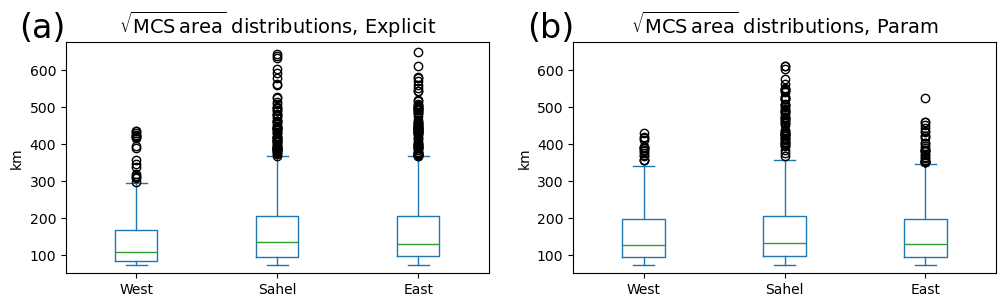

In [9]:
fig, axes=plt.subplots(1,2,figsize=(12,3))

for i,sim in enumerate(sims[::-1]):
    ax=axes[i]
    tab=[]
    mcs=data_dict[sim+"-mcs"][data_dict[sim+"-mcs"].tminlat<20]
    tab.append(11.1**2*mcs.area[(mcs.tminlon<-10)].rename("West"))
    tab.append(11.1**2*mcs.area[(mcs.tminlon>-10) & (mcs.tminlon<10)].rename("Sahel"))
    tab.append(11.1**2*mcs.area[(mcs.tminlon>10)].rename("East"))
    tab=pd.concat(tab,axis=1)

    np.sqrt(tab).plot.box(ax=ax)
    ax.set_title(r"$\sqrt{\rm MCS\, area}$ distributions, "+data_dict[sim+"-tstr"],fontsize=14)
    ax.set_ylabel("km")
    ax.set_ylim([50,675])
    ax.text(-0.11,1.02,"("+string.ascii_lowercase[i]+")",fontsize=24,transform=axes[i].transAxes)
fig.savefig("Figures/MCS_scales_pdfs.png",dpi=400,bbox_inches="tight",facecolor="white")

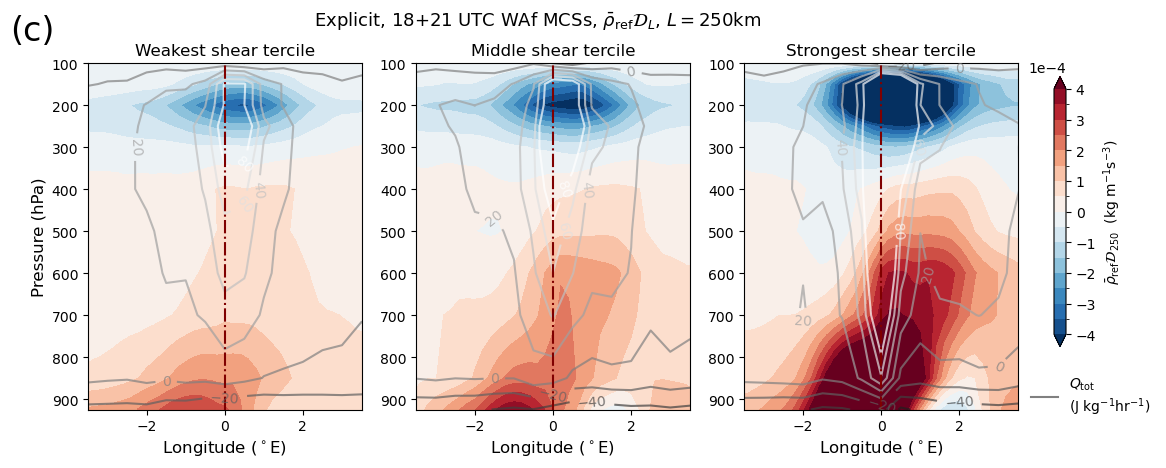

In [10]:
scale=250
ds=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/composites/DY2_CTC_RAL3p2_MCS_shearTer_n640_L={scale}_isetQ_0p2deg.nc")

fig,axes=plt.subplots(1,3,figsize=(12,4.5))
vmax=0.0004
tlabs=["Weakest","Middle","Strongest"]
for i, tercile in enumerate(["t3","t2","t1"]):
    rho_ref=data_dict["ctc_ral3-density_ref"]
    Cb=(rho_ref*ds["Dl_"+tercile].sel(lat=slice(-1.5,1.5))).mean(dim="lat").plot.contourf(ax=axes[i],levels=17,vmax=vmax,extend="both",add_colorbar=False)
    cQ=(3600*ds["Qtot_"+tercile]).sel(latitude=slice(-1.5,1.5)).mean(dim="latitude").plot.contour(ax=axes[i],levels=np.arange(-80,91,20),cmap="grey",alpha=0.7)
    axes[i].clabel(cQ)    
    axes[i].set_ylim([925,100])
    axes[i].set_xlim([-3.5,3.5])
    axes[i].set_xlabel(r"Longitude ($^\circ$E)",fontsize=12)
    axes[i].set_ylabel("")
    axes[i].set_title(tlabs[i]+" shear tercile",fontsize=12)
    axes[i].axvline(0,color="maroon",ls="-.")
axes[0].set_ylabel("Pressure (hPa)",fontsize=12)
fig.suptitle(r"Explicit, 18+21 UTC WAf MCSs, $\bar\rho_{\rm ref}\mathcal{D}_L$, $L=$%skm"%scale,y=1,fontsize=13)

cax = fig.add_axes([0.93,0.25,0.01,0.6])
cbar=fig.colorbar(Cb, cax = cax, orientation = "vertical", extend = "both")#
#cbar=clb.colorbar
cbar.formatter.set_powerlimits((0, 0)) 
cbar.update_ticks()
cbar.set_label(label=r"$\bar\rho_{\rm ref}\mathcal{D}_{%s}$  (kg m$^{-1}$s$^{-3}$)"%scale,fontsize=10)
fig.legend(handles=[Line2D([],[], color="Grey", label=r"$Q_{\rm tot}$"+"\n(J kg$^{-1}$hr$^{-1}$)")], 
              fontsize=10, bbox_to_anchor=(0.9,0.14), frameon=False ,loc="center left")
fig.text(0.06,0.93,"(c)",fontsize=24)
fig.savefig("Figures/MCS_transfer_shear_composites.png",dpi=400,bbox_inches="tight",facecolor="white")

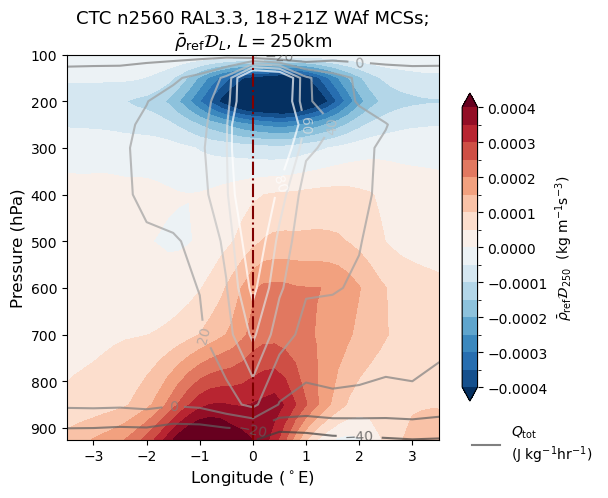

In [11]:
scale=250
ds=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/composites/DY2_CTC_RAL3p2_MCS_shearTer_n640_L={scale}_isetQ_0p2deg.nc")

fig,axes=plt.subplots(figsize=(6,5))
vmax=0.0004
tlabs=["Weakest","Middle","Strongest"]
rho_ref=data_dict["ctc_ral3-density_ref"]
Cb=(rho_ref*ds["Dl_all"].sel(lat=slice(-1.5,1.5))).mean(dim="lat").plot.contourf(ax=axes,levels=17,vmax=vmax,extend="both",
                                                cbar_kwargs={"label":r"$\bar\rho_{\rm ref}\mathcal{D}_{%s}$  (kg m$^{-1}$s$^{-3}$)"%scale,"shrink":0.8})
cbar.formatter.set_powerlimits((0, 0)) 
cbar.update_ticks()
cQ=(3600*ds["Qtot_all"]).sel(latitude=slice(-1.5,1.5)).mean(dim="latitude").plot.contour(ax=axes,levels=np.arange(-80,91,20),cmap="grey",alpha=0.7)
axes.clabel(cQ)    
axes.set_ylim([925,100])
axes.set_xlim([-3.5,3.5])
axes.set_xlabel(r"Longitude ($^\circ$E)",fontsize=12)
axes.set_ylabel("")
axes.set_title(tlabs[i]+" shear tercile",fontsize=12)
axes.axvline(0,color="maroon",ls="-.")
axes.set_ylabel("Pressure (hPa)",fontsize=12)
axes.set_title("CTC n2560 RAL3.3, 18+21Z WAf MCSs;\n"+r"$\bar\rho_{\rm ref}\mathcal{D}_L$, $L=$%skm"%scale,fontsize=13)

fig.legend(handles=[Line2D([],[], color="Grey", label=r"$Q_{\rm tot}$"+"\n(J kg$^{-1}$hr$^{-1}$)")], 
              fontsize=10, bbox_to_anchor=(0.78,0.1), frameon=False ,loc="center left")

In [12]:
def haversine(lon1, lat1, lon2, lat2):
    """
    Calculate the great circle distance in kilometers between two points 
    on the earth (specified in decimal degrees)
    """
    # convert decimal degrees to radians 
    lon1, lat1, lon2, lat2 = map(np.deg2rad, [lon1, lat1, lon2, lat2])

    # haversine formula 
    dlon = lon2 - lon1 
    dlat = lat2 - lat1 
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.sin(np.sqrt(a)) 
    r = 6371 # Radius of earth in kilometers. Use 3956 for miles. Determines return value units.
    return c * r

In [13]:
aew_dists=[]
mcs_data=data_dict["ctc_ral3-mcs"][data_dict["ctc_ral3-mcs"].tminlat<20]

for i in range(len(mcs_data)):
    mcs=mcs_data.iloc[i]
    try:
        aews=data_dict["ctc_ral3-aew_tracks"].sel(time=f"2016-{mcs.month:02d}-{mcs.day:02d} {mcs.hour:02d}")
    except:
        aew_dists.append(np.nan)
        continue
        
    aews=aews.where(~np.isnan(aews.AEW_strength),drop=True)
    mcs_aew_dist=[]
    for j in range(len(aews.system)):
        mcs_aew_dist.append(haversine(mcs.tminlon,mcs.tminlat, aews.AEW_lon[j], aews.AEW_lat[j]))
    aew_dists.append(np.min(mcs_aew_dist))

<Axes: ylabel='Density'>

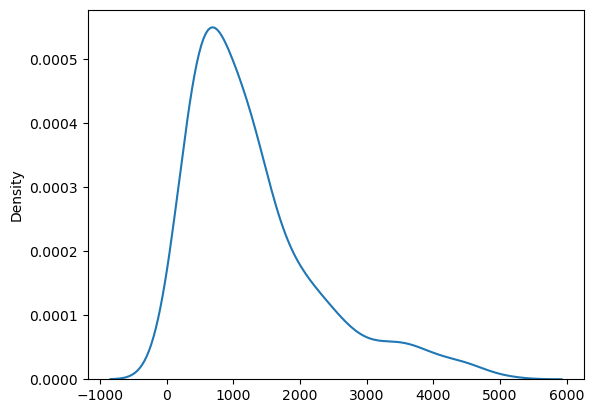

In [14]:
sns.kdeplot(aew_dists)

In [15]:
np.nanmedian(aew_dists)

np.float64(1016.2273252823957)

FIGURE 2

In [16]:
pt=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_{data_dict[sim+"-fstr"]}_thermo_0p5deg.nc")["air_temperature"].sel(
                longitude=slice(-50,30))
pt=mpcalc.potential_temperature(pt.pressure.values[:,None,None,None] * units("hPa"),pt)
pt=pt.mean(dim=["time","longitude"])

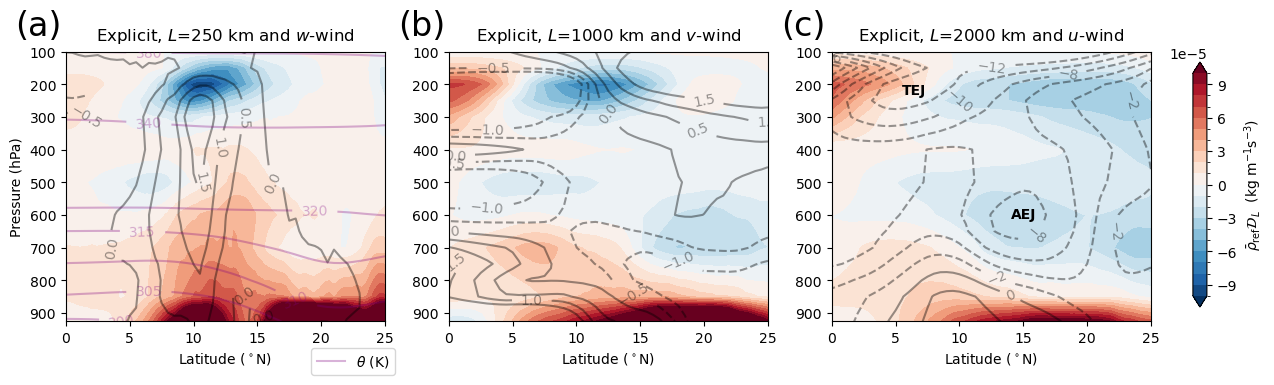

In [17]:
fig,axes=plt.subplots(1,3,figsize=(14,3.5),gridspec_kw={"hspace":0.3})

sim="ctc_ral3"
cont_vars=["upward_air_velocity","y_wind","x_wind"]
for i,l in enumerate([125000,500000,1000000]):
    ax=axes[i]
    cb=(data_dict[sim+"-density_ref"]*data_dict[sim+"-lossett_mean"].Dl_u.sel(length_scale=l,longitude=slice(-50,30))).mean(dim="longitude").plot.contourf(
                                        ax=ax,levels=21,extend="both",vmax=1e-4,add_colorbar=False)
    
    winds=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_{data_dict[sim+"-fstr"]}_dynamics_0p5deg.nc")[cont_vars[i]].mean(dim="time").sel(
                longitude=slice(-50,30)).mean(dim="longitude")
    if i==0:
        Cw,lab_var=(100*winds).plot.contour(ax=ax,levels=[-1,-0.5,0,0.5,1,1.5],colors="k",alpha=0.4),"w"
        Ct=pt.sel(latitude=slice(0,25)).plot.contour(ax=ax,levels=[300,305,310,315,320,340,380],colors="purple",alpha=0.3)
        ax.clabel(Ct)
    elif i==1:
        Cw,lab_var=(winds).plot.contour(ax=ax,levels=[-1,-0.5,0,0.5,1,1.5],colors="k",alpha=0.4),"v"
    elif i==2:
        Cw,lab_var=(winds).plot.contour(ax=ax,levels=np.arange(-12,3,2),colors="k",alpha=0.4),"u"        
    ax.clabel(Cw)
    
    ax.set_ylim([925,100])
    ax.set_xlim([0,25])
    ax.set_title(f"{data_dict[sim+"-tstr"]}, $L$={2*l/1000:.0f} km and ${lab_var}$-wind",pad=8)
    ax.set_ylabel("")
    ax.set_xlabel(r"Latitude ($^\circ$N)")
    ax.text(-4,50,"("+string.ascii_lowercase[i]+")",fontsize=24)
axes[0].set_ylabel("Pressure (hPa)")
axes[2].text(14,610,"AEJ",weight="bold")
axes[2].text(5.5,230,"TEJ",weight="bold")
axes[0].legend(handles=[Line2D([],[], color="purple", alpha=0.3, label=r"$\theta$ (K)")], 
               bbox_to_anchor=(0.9,-0.15), loc="center")

cax = fig.add_axes([0.93,0.15,0.01,0.7])
cbar=fig.colorbar(cb, cax = cax, orientation = "vertical", extend = "both")#
#cbar=clb.colorbar
cbar.formatter.set_powerlimits((0, 0)) 
cbar.update_ticks()
cbar.set_label(label=r"$\bar\rho_{\rm ref}\mathcal{D}_L$  (kg m$^{-1}$s$^{-3}$)",fontsize=10)

fig.savefig("Figures/Zonal_mean_lossett-explicit.png",dpi=200,bbox_inches="tight",facecolor="white")

In [18]:
tseries=data_dict["ctc_ral3-lossett_p200"].time
DR_mean=xr.concat([data_dict[f"ctc_ral3-lossett_p{p}"].groupby(tseries.dt.hour).mean() for p in [850,600,200]],dim="pressure")

In [19]:
tseries=data_dict["ctc_gal9-lossett_p200"].time
DR_mean_GAL=xr.concat([data_dict[f"ctc_gal9-lossett_p{p}"].groupby(tseries.dt.hour).mean() for p in [850,600,200]],dim="pressure")

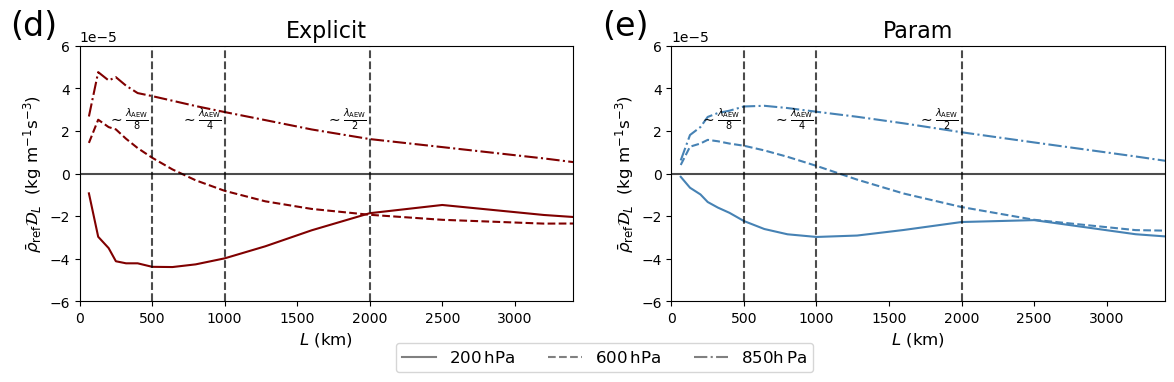

In [20]:
fig,axes=plt.subplots(1,2,figsize=(14,3.5))

hues=["maroon","steelblue"]
for i, data in enumerate([DR_mean,DR_mean_GAL]):
    ax=axes[i]
    ref=data_dict[sims[::-1][i]+"-density_ref"]
    scale_means=ref*data.Dl_u.mean(dim="hour").sel(longitude=slice(-50,30),latitude=slice(5,20)).mean(dim=["longitude","latitude"])
    scale_means.sel(pressure=200).plot(ax=ax,color=hues[i],label="200 hPa")
    scale_means.sel(pressure=600).plot(ax=ax,color=hues[i],ls="--",label="600 hPa")
    scale_means.sel(pressure=850).plot(ax=ax,color=hues[i],ls="-.",label="850 hPa")
    ax.ticklabel_format(axis="y",scilimits=(-0.01,0.01))
    ax.set_ylim([-6e-5,6e-5])
    
    ax.axhline(0,color="k",alpha=0.7)
    for denom in [2,4,8]:
        ax.axvline(1000e3*2/denom,color="k",alpha=0.7,ls="--")
        ax.text(1000e3*2/denom-10e3,.23e-4,r"$\sim\frac{\lambda_{\rm AEW}}{%s}$"%denom,horizontalalignment="right")
    ax.set_xticks(np.arange(0,1.8e6,0.25e6))
    ax.set_xticklabels([str(int(2*x/1000)) for x in np.arange(0,1.8e6,0.25e6)])
    ax.set_xlim([0,1.7e6])
    ax.set_xlabel("$L$ (km)",fontsize=12)
    ax.set_title(data_dict[sims[::-1][i]+"-tstr"],fontsize=16)
    ax.text(-2.4e5,6.5e-5,"("+string.ascii_lowercase[i+3]+")",fontsize=24)
    ax.set_ylabel(r"$\bar\rho_{\rm ref}\mathcal{D}_L$  (kg m$^{-1}$s$^{-3}$)",fontsize=12)

legend_elements = [Line2D([],[],color="grey", marker="", label="200$\,$hPa"),
                   Line2D([],[],color="grey", ls="--", marker="", label="600$\,$hPa"),
                   Line2D([],[],color="grey", ls="-.", marker="", label="850h$\,$Pa")]
fig.subplots_adjust(bottom=0.15)
fig.legend(handles=legend_elements, ncol=3, bbox_to_anchor=(0.5,-0.01), loc="center",fontsize=12)
fig.savefig("Figures/Regional_transfer_spectra.png",dpi=200,bbox_inches="tight",facecolor="white")

FIGURE 3

In [21]:
DR_mean.length_scale

<xarray.DataArray 'length_scale' (length_scale: 17)> Size: 68B
array([  32000.,   64000.,  100000.,  125000.,  160000.,  200000.,  250000.,
        320000.,  400000.,  500000.,  640000.,  800000., 1000000., 1250000.,
       1600000., 2000000., 2500000.], dtype=float32)
Coordinates:
  * length_scale  (length_scale) float32 68B 3.2e+04 6.4e+04 ... 2e+06 2.5e+06
Attributes:
    units:    m

In [22]:
ell_band_S = [32000,125000]
ell_band_MCS = [125000, 250000]
ell_band_M = [250000, 500000]
ell_band_L = [500000, 1000000]
ell_band_XL = [1000000, 2500000]

In [23]:
delta_DR_S = DR_mean.Dl_u.sel(length_scale=ell_band_S[-1]).mean(dim="hour") - DR_mean.Dl_u.sel(length_scale=ell_band_S[0]).mean(dim="hour")
delta_DR_MCS = DR_mean.Dl_u.sel(length_scale=ell_band_MCS[-1]).mean(dim="hour") - DR_mean.Dl_u.sel(length_scale=ell_band_MCS[0]).mean(dim="hour")
delta_DR_M = DR_mean.Dl_u.sel(length_scale=ell_band_M[-1]).mean(dim="hour") - DR_mean.Dl_u.sel(length_scale=ell_band_M[0]).mean(dim="hour")
delta_DR_L = DR_mean.Dl_u.sel(length_scale=ell_band_L[-1]).mean(dim="hour") - DR_mean.Dl_u.sel(length_scale=ell_band_L[0]).mean(dim="hour")
delta_DR_XL = DR_mean.Dl_u.sel(length_scale=ell_band_XL[-1]).mean(dim="hour") - DR_mean.Dl_u.sel(length_scale=ell_band_XL[0]).mean(dim="hour")

In [24]:
delta_DR_Sg = DR_mean_GAL.Dl_u.sel(length_scale=ell_band_S[-1]).mean(dim="hour") - DR_mean_GAL.Dl_u.sel(length_scale=ell_band_S[0]).mean(dim="hour")
delta_DR_MCSg = DR_mean_GAL.Dl_u.sel(length_scale=ell_band_MCS[-1]).mean(dim="hour") - DR_mean_GAL.Dl_u.sel(length_scale=ell_band_MCS[0]).mean(dim="hour")
delta_DR_Mg = DR_mean_GAL.Dl_u.sel(length_scale=ell_band_M[-1]).mean(dim="hour") - DR_mean_GAL.Dl_u.sel(length_scale=ell_band_M[0]).mean(dim="hour")
delta_DR_Lg = DR_mean_GAL.Dl_u.sel(length_scale=ell_band_L[-1]).mean(dim="hour") - DR_mean_GAL.Dl_u.sel(length_scale=ell_band_L[0]).mean(dim="hour")
delta_DR_XLg = DR_mean.Dl_u.sel(length_scale=ell_band_L[-1]).mean(dim="hour") - DR_mean_GAL.Dl_u.sel(length_scale=ell_band_XL[0]).mean(dim="hour")

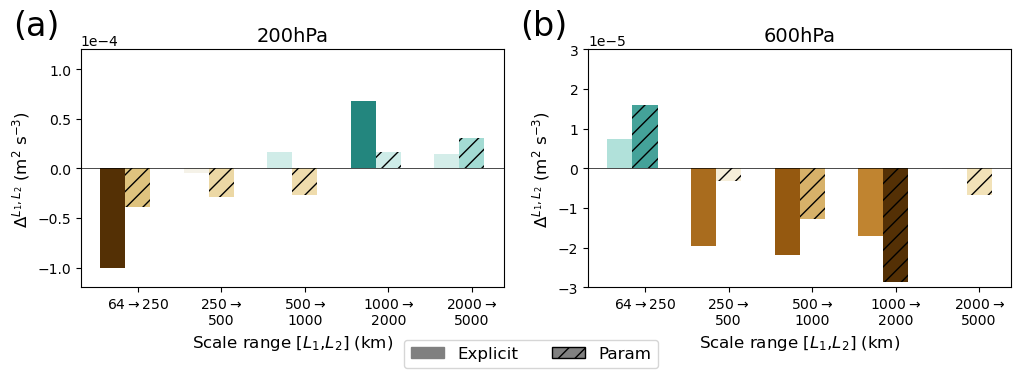

In [25]:
fig,axes = plt.subplots(1,2,figsize=(12,3.5))

for i,lvl in enumerate([200,600]):
    ax=axes[i]
    vals_RAL = [float(delta_DR_S.sel(pressure=lvl,latitude=slice(5,20)).mean(dim=['latitude','longitude'])),\
            float(delta_DR_MCS.sel(pressure=lvl,latitude=slice(5,20)).mean(dim=['latitude','longitude'])),\
            float(delta_DR_M.sel(pressure=lvl,latitude=slice(5,20)).mean(dim=['latitude','longitude'])),\
            float(delta_DR_L.sel(pressure=lvl,latitude=slice(5,20)).mean(dim=['latitude','longitude'])),\
            float(delta_DR_XL.sel(pressure=lvl,latitude=slice(5,20)).mean(dim=['latitude','longitude']))]

    
    vals_GAL = [float(delta_DR_Sg.sel(pressure=lvl,latitude=slice(5,20)).mean(dim=['latitude','longitude'])),\
            float(delta_DR_MCSg.sel(pressure=lvl,latitude=slice(5,20)).mean(dim=['latitude','longitude'])),\
            float(delta_DR_Mg.sel(pressure=lvl,latitude=slice(5,20)).mean(dim=['latitude','longitude'])),\
            float(delta_DR_Lg.sel(pressure=lvl,latitude=slice(5,20)).mean(dim=['latitude','longitude'])),\
            float(delta_DR_XLg.sel(pressure=lvl,latitude=slice(5,20)).mean(dim=['latitude','longitude']))]
    
    sizes = [r"64$\to$250",r"250$\to$"+"\n500",r"500$\to$"+"\n1000",r"1000$\to$"+"\n2000",r"2000$\to$"+"\n5000"]

    penguin_means = {
    'Explicit': vals_RAL,
    'Param' : vals_GAL
    }
    hatches={"Explicit":"","Param":"//"}

    my_cmap = plt.get_cmap("BrBG")
    rescale = lambda y: (y - np.min(vals_RAL+vals_GAL)) / (abs(np.min(vals_RAL+vals_GAL)) - np.min(vals_RAL+vals_GAL))
    
    x = np.arange(len(sizes))  # the label locations
    width = 0.3  # the width of the bars
    multiplier = 0
    
    for attribute, measurement in penguin_means.items():
        offset = width * multiplier
        rects = ax.bar(x + offset, measurement, width, hatch=hatches[attribute], color=my_cmap(rescale(measurement)))
        multiplier += 1
    
    # Add some text for labels, title and custom x-axis tick labels, etc.
    ax.axhline(0,linewidth=0.5,color='k')
    ax.set_ylabel(r'$\Delta^{L_1,L_2}$ (m$^2$ s$^{-3}$)',fontsize=12)
    ax.set_xlabel(r'Scale range [$L_1$,$L_2$] (km)',fontsize=12)
    ax.set_xticks(x + width, sizes)
    ax.set_title("%shPa"%lvl,fontsize=14)
    ax.ticklabel_format(axis="y",scilimits=(-0.01,0.01))
    ax.text(-0.16,1.06,"("+string.ascii_lowercase[i]+")",fontsize=24,transform=axes[i].transAxes)
    
axes[0].set_ylim([-1.2e-4,1.2e-4])
axes[1].set_ylim([-3e-5,3e-5])

legend_elements = [mpatch.Patch(color="grey", label="Explicit"), mpatch.Patch(edgecolor="k", facecolor="grey", hatch="//", label="Param")]
fig.subplots_adjust(bottom=0.2)
fig.legend(handles=legend_elements, fontsize='12', ncol=2, bbox_to_anchor=(0.5,0.01), loc="center")
fig.savefig("Figures/Regional_scale_bands.png",dpi=200,bbox_inches="tight",facecolor="white")

In [26]:
import cartopy.feature as cfeature

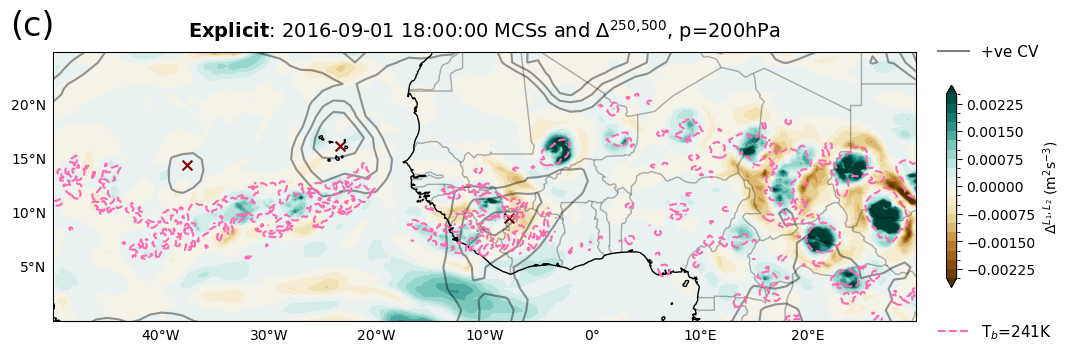

In [27]:
fig,ax=plt.subplots(figsize=(16,3.5),subplot_kw=dict(projection=ccrs.PlateCarree()),gridspec_kw={"hspace":0.1})

pval,sind=200,10
tstamp=pd.Timestamp("2016-09-01 18:00")

Dl=data_dict["ctc_ral3-lossett_p%03d"%pval].sel(time=tstamp,pressure=pval).Dl_u
(Dl.sel(length_scale=ell_band_MCS[-1]) - Dl.sel(length_scale=ell_band_MCS[0])).plot.contourf(ax=ax,vmax=0.0025,extend="both",cmap="BrBG",levels=21,
                                                        cbar_kwargs={"shrink":0.75,"label":r"$\Delta^{L_1,L_2}$ (m$^2$s$^{-3}$)","pad":0.025})

cv=xr.open_dataset("~/QTrack/CTC_RAL3p2_curv_vort.nc").curv_vort.sel(time=tstamp,method="nearest")
Cv=cv.plot.contour(ax=ax,levels=[2e-6,4e-6,6e-6],colors="black",alpha=0.4)
data_dict["ctc_ral3-aew_tracks"].sel(time=tstamp).plot.scatter(ax=ax,x="AEW_lon",y="AEW_lat",s=50,color="maroon",marker="x")


bt=xr.open_dataset("/gws/ssde/j25b/kscale/DATA/outdir_20160801T0000Z/DMn1280GAL9/channel_n2560_RAL3p2/single_olwr/20160901_20160801T0000Z_channel_olwr_hourly.nc"
                  ).toa_outgoing_longwave_flux.sel(longitude=slice(-50,30),latitude=slice(0,25)).sel(time=tstamp,method="nearest")
bt=tb_from_olr(bt)
bt.plot.contour(ax=ax,levels=[241],colors="hotpink",linestyles="--",alpha=1)

ax.coastlines()
ax.add_feature(cfeature.BORDERS,alpha=0.3)
ax.set_title(r"$\rm\mathbf{Explicit}$: "+str(tstamp)+
             r" MCSs and $\Delta^{250,\!500}$, p=%shPa"%pval,
             fontsize=14,pad=10)
gl=ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
gl.ylines = False
gl.xlines = False

ax.set_ylim([0,25])
ax.set_xlim([-50,30])
ax.text(-54,26.5,"(c)",fontsize=24)
fig.legend(handles=[Line2D([],[], color="hotpink", ls="--", alpha=1, label=r"T$_b$=241K")], 
               bbox_to_anchor=(0.77,0.08), frameon=False ,loc="center left",fontsize=11)
fig.legend(handles=[Line2D([],[], color="k", alpha=0.5, label=r"+ve CV")], 
               bbox_to_anchor=(0.77,0.88), frameon=False ,loc="center left",fontsize=11)
fig.savefig("Figures/Explicit_spatial_snapshot_MCS_transfer_250-500.png",dpi=200,bbox_inches="tight",facecolor="white")

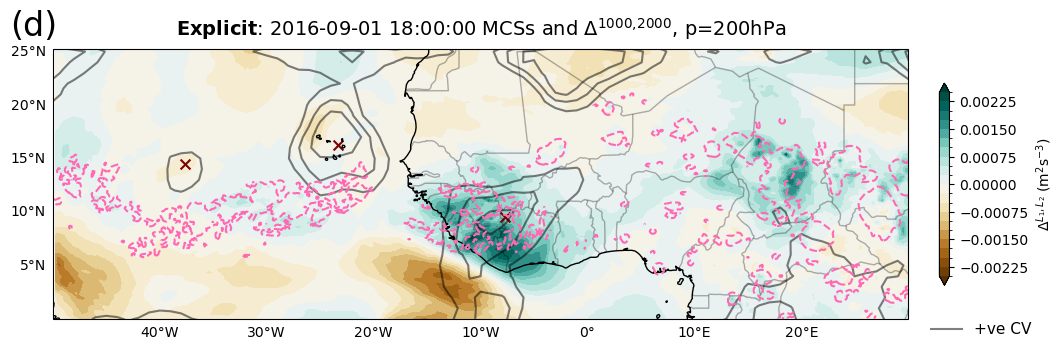

In [28]:
#"""
fig,ax=plt.subplots(figsize=(16,3.5),subplot_kw=dict(projection=ccrs.PlateCarree()),gridspec_kw={"hspace":0.1})

ax.set_extent([-50,30,0,20])
pval,sind=200,10
tstamp=pd.Timestamp("2016-09-01 18:00")

Dl=data_dict["ctc_ral3-lossett_p%03d"%pval].sel(time=tstamp,pressure=pval).Dl_u
(Dl.sel(length_scale=ell_band_L[-1]) - Dl.sel(length_scale=ell_band_L[0])).plot.contourf(ax=ax,vmax=0.0025,extend="both",cmap="BrBG",levels=21,
                                                        cbar_kwargs={"shrink":0.75,"label":r"$\Delta^{L_1,L_2}$ (m$^2$s$^{-3}$)","pad":0.025})
Cv=cv.plot.contour(ax=ax,levels=[2e-6,4e-6,6e-6],colors="black",alpha=0.5)
data_dict["ctc_ral3-aew_tracks"].sel(time=tstamp).plot.scatter(ax=ax,x="AEW_lon",y="AEW_lat",s=50,color="maroon",marker="x")
bt.plot.contour(ax=ax,levels=[241],colors="hotpink",linestyles="--",alpha=1)
#sep_tracks[(sep_tracks.time==tstamp.replace(minute=2)) &
#            (sep_tracks.area>100)].plot.scatter(ax=ax,x="clon",y="clat",marker="x",color="purple",s=35)
#ax.legend()
ax.coastlines()
ax.add_feature(cfeature.BORDERS,alpha=0.3)
ax.set_title(r"$\rm\mathbf{Explicit}$: "+str(tstamp)+
             r" MCSs and $\Delta^{1000,\!2000}$, p=%shPa"%pval, 
             fontsize=14,pad=10)
gl=ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
gl.ylines = False
gl.xlines = False

ax.text(-54,26.5,"(d)",fontsize=24)
fig.legend(handles=[Line2D([],[], color="k", alpha=0.5, label=r"+ve CV")], 
               bbox_to_anchor=(0.77,0.08), frameon=False ,loc="center left",fontsize=11)
fig.savefig("Figures/Explicit_spatial_snapshot_MCS_transfer_1000-2000.png",dpi=200,bbox_inches="tight",facecolor="white")

In [29]:
dyn=xr.open_dataset("/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_CTC_RAL3p2_dynamics_0p5deg.nc")

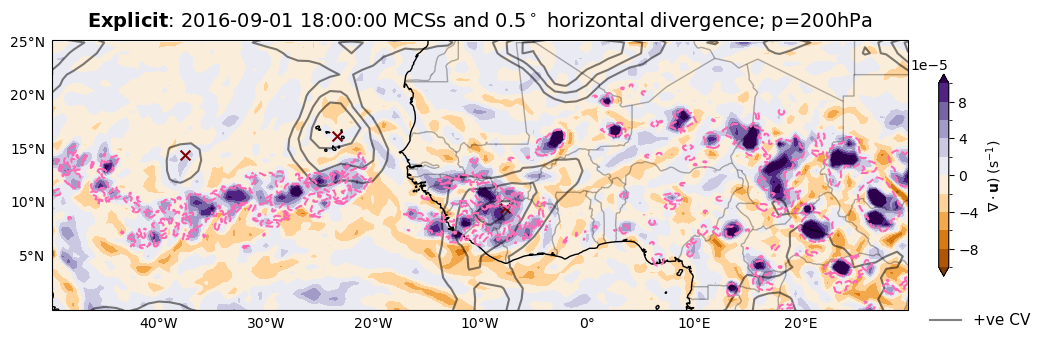

In [30]:
#"""
fig,ax=plt.subplots(figsize=(16,3.5),subplot_kw=dict(projection=ccrs.PlateCarree()),gridspec_kw={"hspace":0.1})

ax.set_extent([-50,30,0,20])
pval,sind=200,10
tstamp=pd.Timestamp("2016-09-01 18:00")

dyn.horizontal_divergence.sel(time=tstamp,pressure=pval).plot.contourf(ax=ax,extend="both",cmap="PuOr",levels=11,vmax=0.0001,
                                                        cbar_kwargs={"shrink":0.75,"label":r"$\nabla\cdot\mathbf{u})$ (s$^{-1}$)","pad":0.025})

Cv=cv.plot.contour(ax=ax,levels=[2e-6,4e-6,6e-6],colors="black",alpha=0.5)
data_dict["ctc_ral3-aew_tracks"].sel(time=tstamp).plot.scatter(ax=ax,x="AEW_lon",y="AEW_lat",s=50,color="maroon",marker="x")
bt.plot.contour(ax=ax,levels=[241],colors="hotpink",linestyles="--",alpha=1)
ax.coastlines()
ax.add_feature(cfeature.BORDERS,alpha=0.3)
ax.set_title(r"$\rm\mathbf{Explicit}$: "+str(tstamp)+
             r" MCSs and 0.5$^\circ$ horizontal divergence; p=%shPa"%(pval),
             fontsize=14,pad=10)
gl=ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
gl.ylines = False
gl.xlines = False

#ax.text(-54,26.5,"(d)",fontsize=24)
fig.legend(handles=[Line2D([],[], color="k", alpha=0.5, label=r"+ve CV")], 
               bbox_to_anchor=(0.77,0.08), frameon=False ,loc="center left",fontsize=11)

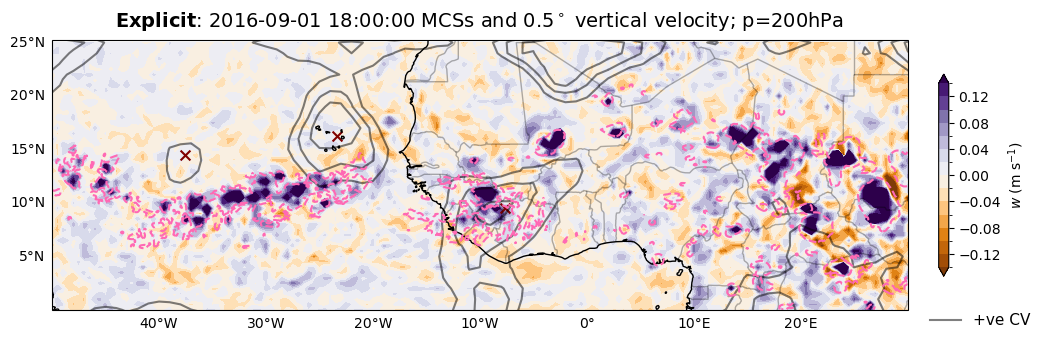

In [31]:
#"""
fig,ax=plt.subplots(figsize=(16,3.5),subplot_kw=dict(projection=ccrs.PlateCarree()),gridspec_kw={"hspace":0.1})

ax.set_extent([-50,30,0,20])
pval,sind=200,10
tstamp=pd.Timestamp("2016-09-01 18:00")

dyn.upward_air_velocity.sel(time=tstamp,pressure=pval).plot.contourf(ax=ax,extend="both",cmap="PuOr",levels=15,vmax=0.14,
                                                        cbar_kwargs={"shrink":0.75,"label":r"$w$ (m s$^{-1}$)","pad":0.025})

Cv=cv.plot.contour(ax=ax,levels=[2e-6,4e-6,6e-6],colors="black",alpha=0.5)
data_dict["ctc_ral3-aew_tracks"].sel(time=tstamp).plot.scatter(ax=ax,x="AEW_lon",y="AEW_lat",s=50,color="maroon",marker="x")
bt.plot.contour(ax=ax,levels=[241],colors="hotpink",linestyles="--",alpha=1)

ax.coastlines()
ax.add_feature(cfeature.BORDERS,alpha=0.3)
ax.set_title(r"$\rm\mathbf{Explicit}$: "+str(tstamp)+
             r" MCSs and 0.5$^\circ$ vertical velocity; p=%shPa"%(pval),
             fontsize=14,pad=10)
gl=ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
gl.ylines = False
gl.xlines = False

#ax.text(-54,26.5,"(d)",fontsize=24)
fig.legend(handles=[Line2D([],[], color="k", alpha=0.5, label=r"+ve CV")], 
               bbox_to_anchor=(0.77,0.08), frameon=False ,loc="center left",fontsize=11)

FIGURE 4

In [32]:
palette=sns.color_palette("hls", 25)

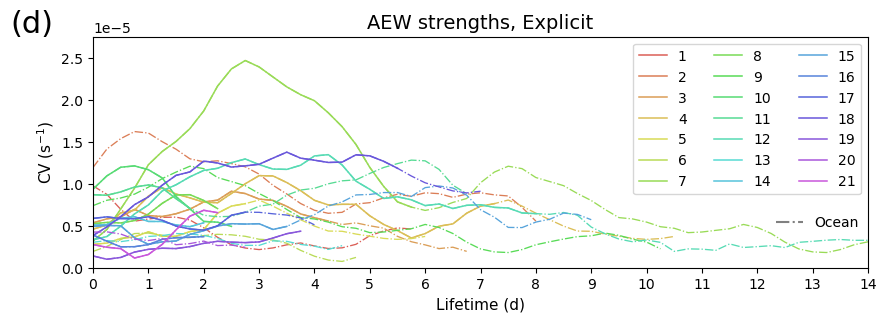

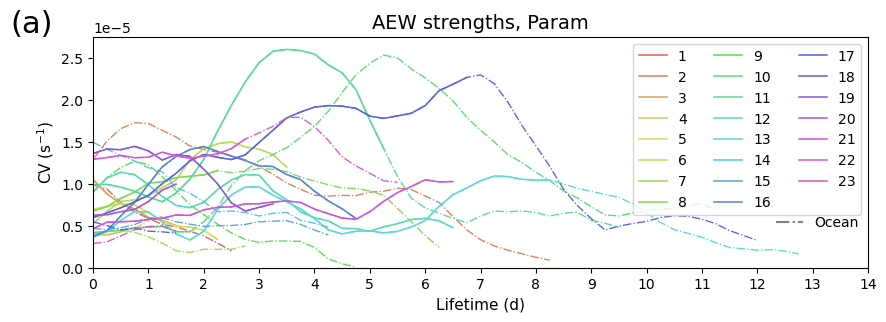

In [33]:
for sim in ["ctc_ral3","ctc_gal9"]:
    fig,ax=plt.subplots(figsize=(10,3))
    aew_tracks=data_dict[sim+"-aew_tracks"].rolling(time=4).mean()
    for s in data_dict[sim+"-aew_tracks"].system.values:
        wave=aew_tracks.where((aew_tracks.system==s) & (aew_tracks.AEW_strength>0),drop=True).isel(system=0)
        t0=wave.time.values[0]
        ax.plot(np.arange(len(wave.AEW_strength)), wave.AEW_strength.values,ls="-.",color=palette[int(s-1)],lw=0.95)
    
        try:
            land=wave.where(wave.AEW_lon_smooth>-18,drop=True)
            tL=np.arange(len(land.AEW_strength))
            ax.plot(tL,land.AEW_strength.values,label=str(int(s)),color=palette[int(s-1)],lw=1.1)
        except:
            pass
    ax.legend(ncol=3)
    ax.set_xlim([0,3])
    ax.set_ylim([0,2.75e-5])
    ax.set_xticks(np.arange(0,57,4))
    ax.set_xticklabels([int(i/4) for i in np.arange(0,57,4)])
    ax.set_xlabel("Lifetime (d)",fontsize=11)
    ax.set_ylabel("CV (s$^{-1}$)",fontsize=11)
    ax.set_title("AEW strengths, "+data_dict[sim+"-tstr"],fontsize=14)
    fig.legend(handles=[Line2D([],[], color="grey", ls="-.", label=r"Ocean")], 
              fontsize=10, bbox_to_anchor=(0.795,0.26), frameon=False ,loc="center left")
    if sim=="ctc_ral3":
        ax.text(-6,2.8e-5,"(d)",fontsize=22)
        fig.savefig("Figures/Explicit_AEW_strengths.png",dpi=200,bbox_inches="tight",facecolor="white")
    elif sim=="ctc_gal9":
        ax.text(-6,2.8e-5,"(a)",fontsize=22)
        fig.savefig("Figures/Param_AEW_strengths.png",dpi=200,bbox_inches="tight",facecolor="white")

In [84]:
for sim in sims:
    print(f"Median {data_dict[sim+"-tstr"]} AEW strength: ",float(data_dict[sim+"-aew_tracks"].AEW_strength.median()))
    print(f"Mean {data_dict[sim+"-tstr"]} AEW latitude: ",float(data_dict[sim+"-aew_tracks"].AEW_lat_smooth.mean()))
print("% Increase of ",float((data_dict["ctc_gal9-aew_tracks"].AEW_strength.median()-data_dict["ctc_ral3-aew_tracks"].AEW_strength.median()
                     )/data_dict["ctc_ral3-aew_tracks"].AEW_strength.median()*100))

Median Param AEW strength:  7.615076731985074e-06
Mean Param AEW latitude:  12.985882901754417
Median Explicit AEW strength:  5.24539782892738e-06
Mean Explicit AEW latitude:  13.741622306551834
% Increase of  45.17634277402872


Explicit wave speed comparisons over land-regions shown in case study plots

In [85]:
ds=data_dict["ctc_ral3-aew_tracks"].AEW_lon_smooth
ds=ds.where((ds>-18) & (ds<15),drop=True)
speed=float(ds.differentiate("time",datetime_unit="s").mean())
print("Mean wave speed (m/s):",speed*110*1000)

Mean wave speed (m/s): -7.64299065465718


In [86]:
# Focus in on case-study system
ds7=data_dict["ctc_ral3-aew_tracks"].sel(system=7).AEW_lon_smooth
ds7=ds7.where((ds7>-18) & (ds7<15),drop=True)
print("Mean case-study wave speed (m/s),",float(ds7.differentiate("time",datetime_unit="s").mean())*110*1000)

Mean case-study wave speed (m/s), -7.274530765765421


([<matplotlib.axis.XTick at 0x7f3a7540a480>,
 [Text(1, 0, 'All waves'), Text(2, 0, 'Wave 7')])

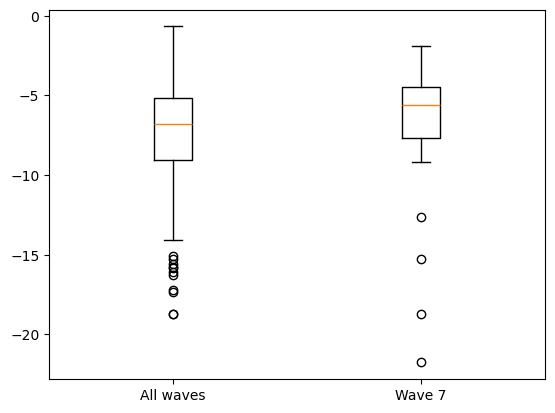

In [87]:
# The means are similar, but the distributions are very different between the two samples:
all_wave_speeds=110*1000*ds.differentiate("time",datetime_unit="s").values.flatten()
case_wave_speeds=110*1000*ds7.differentiate("time",datetime_unit="s").values.flatten()

plt.boxplot([all_wave_speeds[~np.isnan(all_wave_speeds)],
             case_wave_speeds[~np.isnan(case_wave_speeds)]])
plt.xticks(ticks=[1,2],labels=["All waves","Wave 7"])

In [88]:
print("Median all wave speed (m/s):",np.nanmedian(all_wave_speeds))
print("Median case study wave speed (m/s):",np.nanmedian(case_wave_speeds))
print("Difference",np.nanmedian(case_wave_speeds)-np.nanmedian(all_wave_speeds))

Median all wave speed (m/s): -6.769879405709086
Median case study wave speed (m/s): -5.614080060060243
Difference 1.155799345648843


FIGURE 5

In [44]:
comp_dict={}
for sim in ["ctc_ral3","ctc_gal9"]:
    for phase in ["growth","prop","ocean"]:
        for field in ["isetQ","dynamics","thermodynamics"]:
            try:
                comp_dict[sim+"-"+phase+"_"+field]=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/composites/DY2_{data_dict[sim+"-fstr"]}_aew_{phase}_n640_{field}_0p2deg.nc")
            except:
                comp_dict[sim+"-"+phase+"_"+field]=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/composites/DY2_{data_dict[sim+"-fstr"]}_aew_{phase}_{field}_0p5deg.nc")            

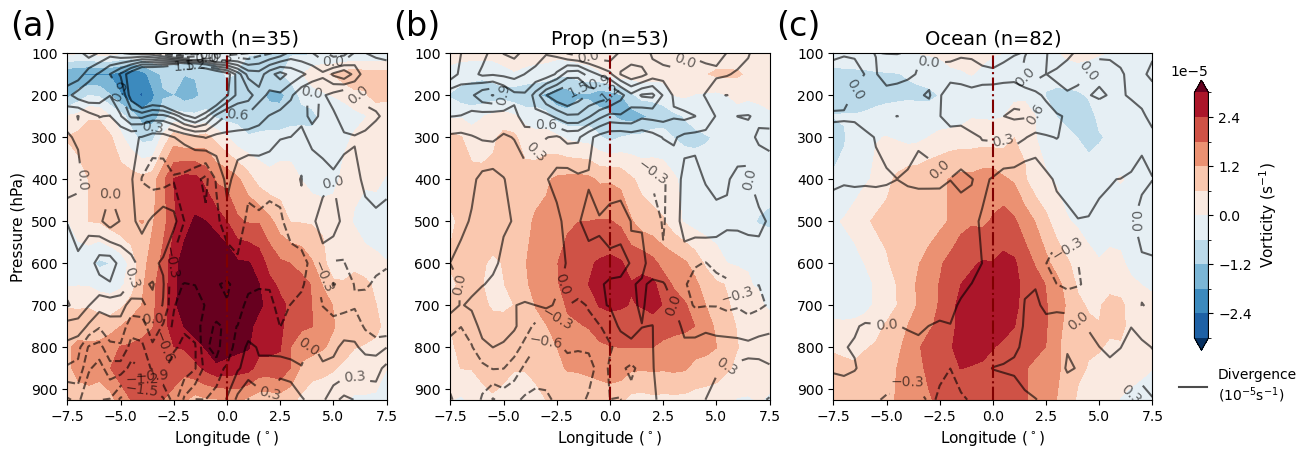

In [45]:
phases=["growth","prop","ocean"]

sim="ctc_ral3"
fig,axes=plt.subplots(1,3,figsize=(14,4.5))
for i, phase in enumerate(["growth","prop","ocean"]):
    ax=axes[i]
    Cb=comp_dict[sim+"-"+phase+"_dynamics"].vertical_vorticity_mean.sel(latitude=slice(-3.5,3.5)).mean(dim="latitude"
                                                    ).plot.contourf(ax=ax,vmax=3e-5,levels=11,extend="both",add_colorbar=False)
    cQ=(1e5*comp_dict[sim+"-"+phase+"_dynamics"].horizontal_divergence_mean).sel(latitude=slice(-3.5,3.5)).mean(dim="latitude"
                                                    ).plot.contour(ax=ax,levels=np.arange(-1.5,1.51,0.3),colors="Black",alpha=0.6)
    ax.clabel(cQ)
    ax.set_ylim([925,100])
    ax.set_title(phase.capitalize()+" (n=%s)"%comp_dict[sim+"-"+phase+"_dynamics"].attrs["number_cores"],fontsize=14)
    ax.axvline(0,ls="-.",color="maroon")
    ax.set_ylabel("")
    ax.set_xlabel(r"Longitude ($^\circ$)",fontsize=11)
    ax.text(-0.18,1.05,"("+string.ascii_lowercase[i]+")",fontsize=24,transform=axes[i].transAxes)
axes[0].set_ylabel("Pressure (hPa)",fontsize=11)

cax = fig.add_axes([0.93,0.22,0.01,0.6])
clb=fig.colorbar(Cb, cax = cax, orientation = "vertical", extend = "both").set_label(label=r"Vorticity (s$^{-1}$)",fontsize=11)


fig.legend(handles=[Line2D([],[], color="Black", alpha=0.7, label="Divergence\n(10$^{-5}$s$^{-1}$)")],#"r"$\nabla\cdot\mathbf{V}$"+"\n(10$^{-5}$s$^{-1}$)")], 
              fontsize=10, bbox_to_anchor=(0.91,0.14), frameon=False ,loc="center left")
fig.savefig("Figures/AEW_phase_vorticity_div_composites.png",dpi=200,bbox_inches="tight",facecolor="white")

FIGURE 6

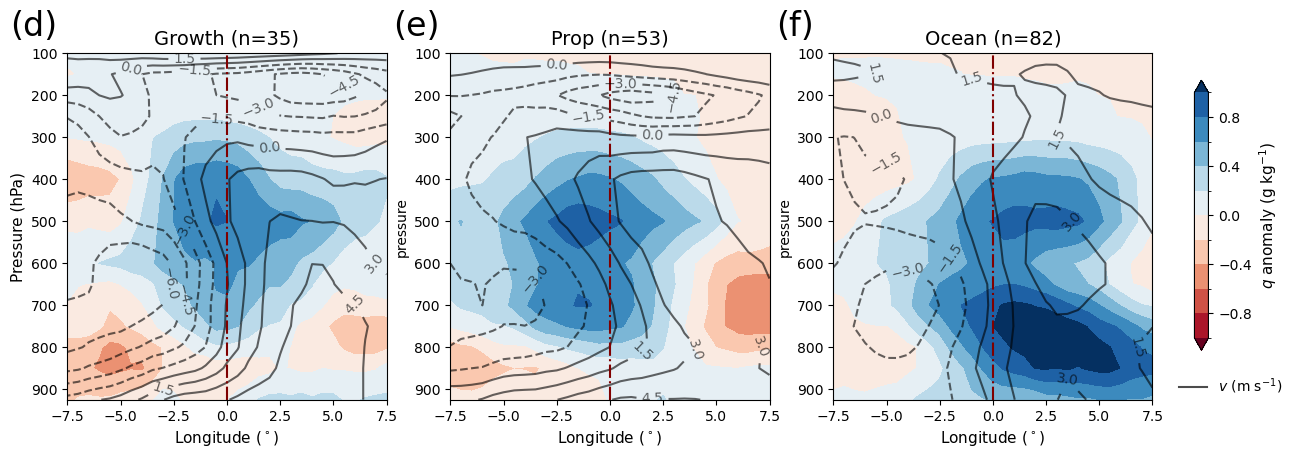

In [46]:
phases=["growth","prop","ocean"]

sim="ctc_ral3"
fig,axes=plt.subplots(1,3,figsize=(14,4.5))
for i, phase in enumerate(["growth","prop","ocean"]):
    ax=axes[i]
    Cb=(1000*comp_dict[sim+"-"+phase+"_thermodynamics"].q_anom_mean).sel(latitude=slice(-3.5,3.5)).mean(dim="latitude"
                                                    ).plot.contourf(ax=ax,vmax=1,levels=11,cmap="RdBu",extend="both",add_colorbar=False)
    #cQ=(comp_dict[phase+"_thermodynamics"].theta_e_anom_mean).sel(latitude=slice(-3.5,3.5)).mean(dim="latitude"
    #                                                ).plot.contour(ax=ax,levels=np.arange(-4,4.1),colors="Black",alpha=0.6)
    cQ=(comp_dict[sim+"-"+phase+"_dynamics"].y_wind_mean).sel(latitude=slice(-3.5,3.5)).mean(dim="latitude"
                                                    ).plot.contour(ax=ax,levels=np.arange(-6,6.1,1.5),colors="Black",alpha=0.6)
    ax.clabel(cQ)
    ax.set_ylim([925,100])
    ax.set_title(phase.capitalize()+" (n=%s)"%comp_dict[sim+"-"+phase+"_dynamics"].attrs["number_cores"],fontsize=14)
    ax.axvline(0,ls="-.",color="maroon")
    ax.set_xlabel(r"Longitude ($^\circ$)",fontsize=11)
    ax.text(-0.18,1.05,"("+string.ascii_lowercase[i+3]+")",fontsize=24,transform=axes[i].transAxes)
axes[0].set_ylabel("Pressure (hPa)",fontsize=11)

cax = fig.add_axes([0.93,0.22,0.01,0.6])
clb=fig.colorbar(Cb, cax = cax, orientation = "vertical", extend = "both").set_label(label=r"$q$ anomaly (g kg$^{-1}$)",fontsize=11)

fig.legend(handles=[Line2D([],[], color="Black", alpha=0.7, label=r"$v$ (m s$^{-1}$)")], 
              fontsize=10, bbox_to_anchor=(0.91,0.14), frameon=False ,loc="center left")
fig.savefig("Figures/AEW_phase_q_v_composites.png",dpi=200,bbox_inches="tight",facecolor="white")

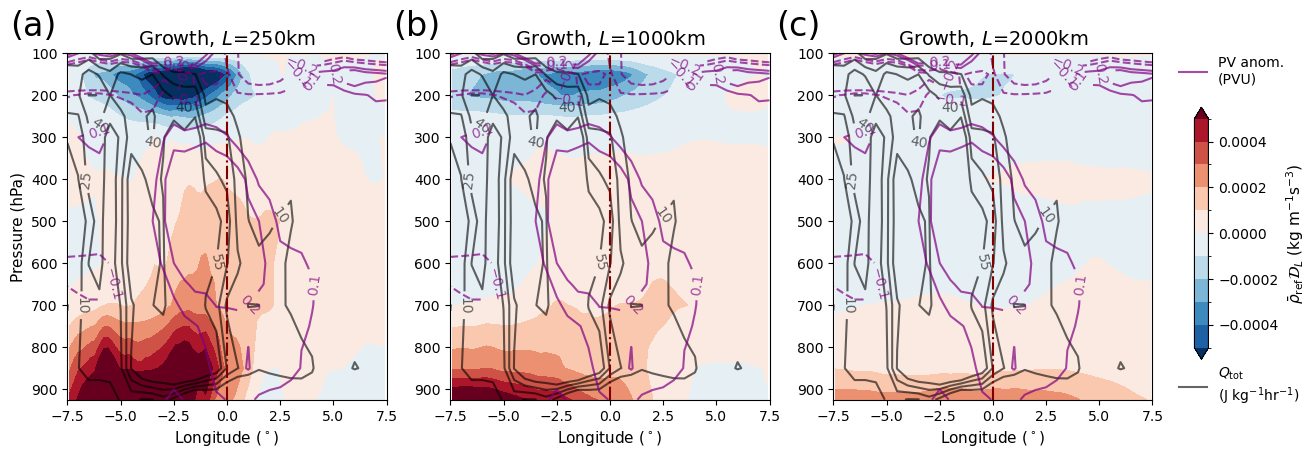

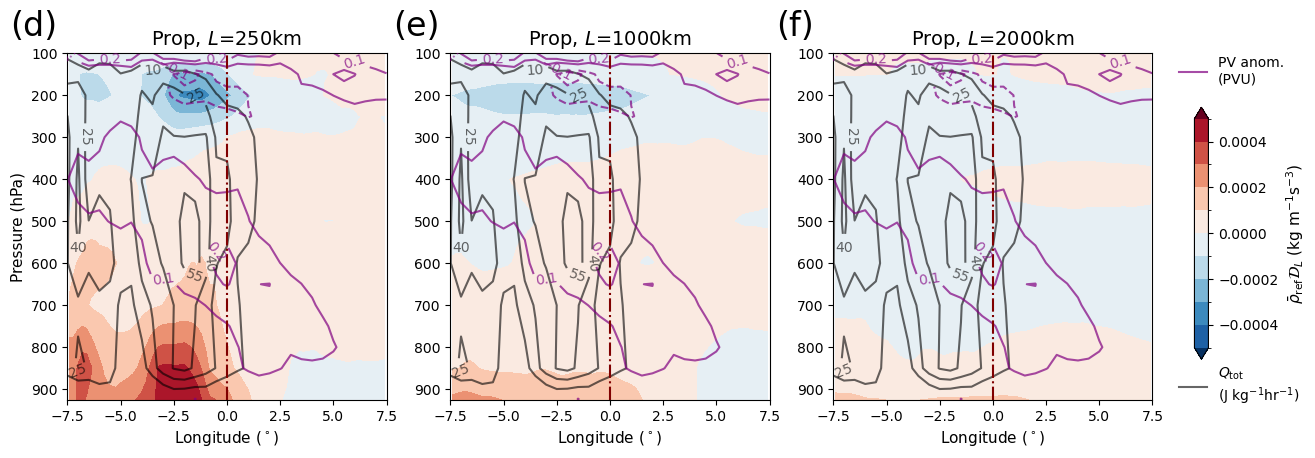

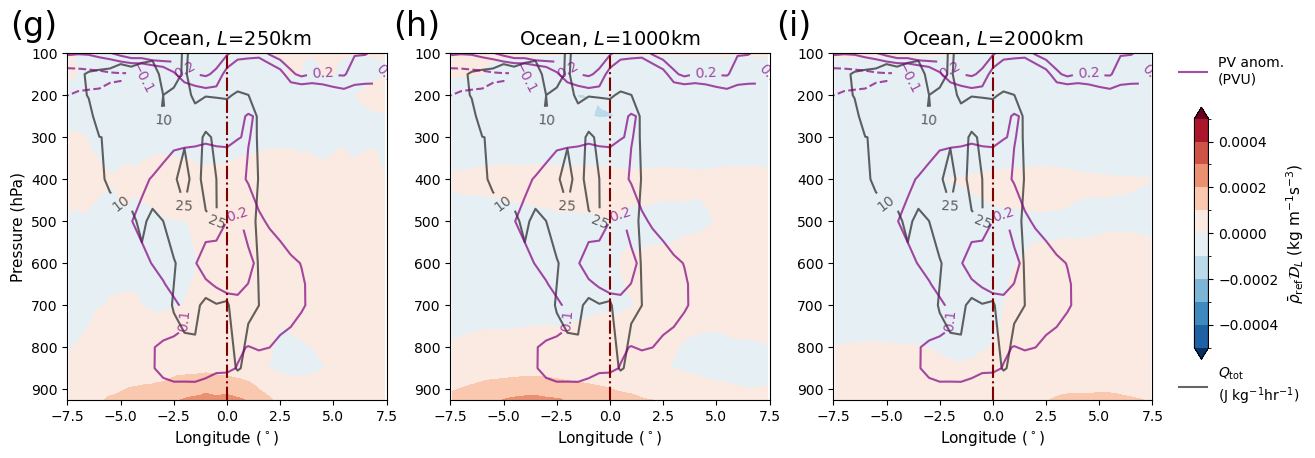

In [47]:
phases=["growth","prop","ocean"]
scales=[125,500,1000]
for j, phase in enumerate(phases):
    fig,axes=plt.subplots(1,3,figsize=(14,4.5))
    for i, scale in enumerate(scales):
        ax=axes[i]
        data=(data_dict[sim+"-density_ref"]*comp_dict[sim+"-"+phase+"_isetQ"].Dl_u_mean.sel(length_scale=scale)).sel(lat=slice(-3.5,3.5)).mean(dim="lat")
        Cb=data.plot.contourf(ax=ax,vmax=0.0005,levels=11,extend="both",add_colorbar=False)
        cQ=(3600*comp_dict[sim+"-"+phase+"_isetQ"].Q_tot_mean).sel(latitude=slice(-3.5,3.5)).mean(dim="latitude"
                                                    ).plot.contour(ax=ax,levels=np.arange(10,56,15),colors="k",alpha=0.6)
        ax.clabel(cQ)
        cPV=(1e6*comp_dict[sim+"-"+phase+"_dynamics"].pv_anom_mean).sel(latitude=slice(-1.5,1.5)).mean(dim="latitude"
                                                    ).plot.contour(ax=ax,levels=[-0.2,-0.1,0.1,0.2],colors="Purple",alpha=0.7)
        ax.clabel(cPV)
        std=comp_dict[sim+"-"+phase+"_isetQ"].Dl_u_std.sel(length_scale=scale).sel(lat=slice(-3.5,3.5)).mean(dim="lat")
        N=comp_dict[sim+"-"+phase+"_dynamics"].attrs["number_cores"]
        t=data/(std/np.sqrt(N))
        data.values=stats.t.sf(np.abs(t), N-1)
        #data.plot.contourf(ax=ax,colors="none",levels=[0,0.05],hatches=[".",""],add_colorbar=False)
        ax.set_ylim([925,100])
        ax.set_title(phase.capitalize()+", $L$=%.0fkm"%(2*scale),fontsize=14)
        ax.axvline(0,ls="-.",color="maroon")
        ax.set_ylabel("")
        ax.set_xlabel(r"Longitude ($^\circ$)",fontsize=11)
        ax.text(-0.18,1.05,"("+string.ascii_lowercase[i+3*j]+")",fontsize=24,transform=axes[i].transAxes)
    axes[0].set_ylabel("Pressure (hPa)",fontsize=11)
    
    cax = fig.add_axes([0.93,0.2,0.01,0.56])
    clb=fig.colorbar(Cb, cax = cax, orientation = "vertical", extend = "both").set_label(label=r"$\bar\rho_{\rm ref}\mathcal{D}_L$ (kg m$^{-1}$s$^{-3}$)",fontsize=11)

    
    fig.legend(handles=[Line2D([],[], color="k", alpha=0.6, label=r"$Q_{\rm tot}$"+"\n(J kg$^{-1}$hr$^{-1}$)")], 
                  fontsize=10, bbox_to_anchor=(0.91,0.14), frameon=False ,loc="center left")
    fig.legend(handles=[Line2D([],[], color="Purple", alpha=0.7, label="PV anom.\n(PVU)")], 
                  fontsize=10, bbox_to_anchor=(0.91,0.84), frameon=False ,loc="center left")
    #fig.suptitle(data_dict[sim+"-tstr"])
    fig.savefig(f"Figures/AEW_{phase}_lossett_composites.png",dpi=200,bbox_inches="tight",facecolor="white")

FIG S6

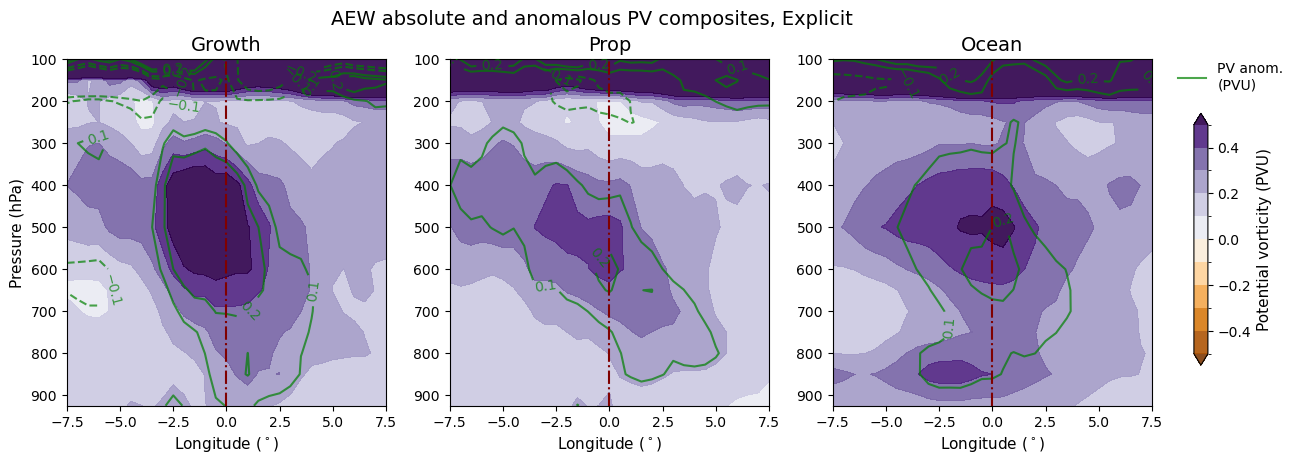

In [48]:
fig,axes=plt.subplots(1,3,figsize=(14,4.5))

for j, phase in enumerate(["growth","prop","ocean"]):
    ax=axes[j]
    Cb=(1e6*comp_dict[sim+"-"+phase+"_dynamics"].pv_mean).sel(latitude=slice(-1.5,1.5)).mean(dim="latitude"
                                                ).plot.contourf(ax=ax,levels=np.arange(-0.5,0.6,0.1),cmap="PuOr",extend="both",alpha=0.9,add_colorbar=False)
    cPV=(1e6*comp_dict[sim+"-"+phase+"_dynamics"].pv_anom_mean).sel(latitude=slice(-1.5,1.5)).mean(dim="latitude"
                                                ).plot.contour(ax=ax,levels=[-0.2,-0.1,0.1,0.2],colors="green",alpha=0.7)
    ax.clabel(cPV)
    ax.set_ylim([925,100])
    ax.set_title(phase.capitalize(),fontsize=14)
    ax.axvline(0,ls="-.",color="maroon")
    ax.set_ylabel("")
    ax.set_xlabel(r"Longitude ($^\circ$)",fontsize=11)
axes[0].set_ylabel("Pressure (hPa)",fontsize=11)

cax = fig.add_axes([0.93,0.2,0.01,0.56])
clb=fig.colorbar(Cb, cax = cax, orientation = "vertical", extend = "both").set_label(label=r"Potential vorticity (PVU)",fontsize=11)

fig.legend(handles=[Line2D([],[], color="Green", alpha=0.7, label="PV anom.\n(PVU)")], 
              fontsize=10, bbox_to_anchor=(0.91,0.84), frameon=False ,loc="center left")
fig.suptitle("AEW absolute and anomalous PV composites, Explicit",fontsize=14,y=0.99)
fig.savefig(f"Figures/SuppFig_explicit_AEW_PV_composites.png",dpi=200,bbox_inches="tight",facecolor="white")

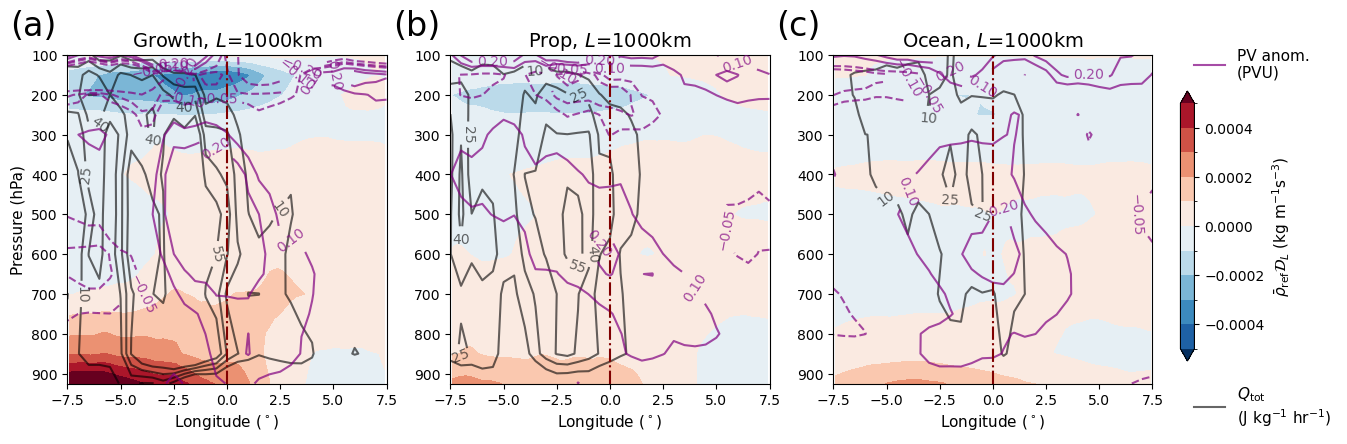

In [49]:
phases=["growth","prop","ocean"]
sim="ctc_ral3"
scales=[500]
for j, scale in enumerate(scales):
    fig,axes=plt.subplots(1,3,figsize=(14,4.5))
    for i, phase in enumerate(phases):
        ax=axes[i]
        data=(data_dict[sim+"-density_ref"]*comp_dict[sim+"-"+phase+"_isetQ"].Dl_u_mean.sel(length_scale=scale)).sel(lat=slice(-3.5,3.5)).mean(dim="lat")
        Cb=data.plot.contourf(ax=ax,vmax=0.0005,levels=11,extend="both",add_colorbar=False)
        cQ=(3600*comp_dict[sim+"-"+phase+"_isetQ"].Q_tot_mean).sel(latitude=slice(-3.5,3.5)).mean(dim="latitude"
                                                    ).plot.contour(ax=ax,levels=np.arange(10,56,15),colors="k",alpha=0.6)
        ax.clabel(cQ)
        cPV=(1e6*comp_dict[sim+"-"+phase+"_dynamics"].pv_anom_mean).sel(latitude=slice(-1.5,1.5)).mean(dim="latitude"
                                                    ).plot.contour(ax=ax,levels=[-0.2,-0.1,-0.05,0.1,0.2],colors="Purple",alpha=0.7)
        ax.clabel(cPV)
        #data.plot.contourf(ax=ax,colors="none",levels=[0,0.05],hatches=[".",""],add_colorbar=False)
        ax.set_ylim([925,100])
        ax.set_title(f"{phase.capitalize()}, $L$={2*scale:.0f}km",fontsize=14)
        ax.axvline(0,ls="-.",color="maroon")
        ax.set_ylabel("")
        ax.set_xlabel(r"Longitude ($^\circ$)",fontsize=11)
        ax.text(-0.18,1.06,"("+string.ascii_lowercase[i]+")",fontsize=24,transform=axes[i].transAxes)
    axes[0].set_ylabel("Pressure (hPa)",fontsize=11)

    fig.subplots_adjust(bottom=0.15)
    cax = fig.add_axes([0.92,0.2,0.01,0.6])
    clb=fig.colorbar(Cb, cax = cax, orientation = "vertical", extend = "both").set_label(label=r"$\bar\rho_{\rm ref}\mathcal{D}_L$ (kg m$^{-1}$s$^{-3}$)",fontsize=11)

    
    fig.legend(handles=[Line2D([],[], color="k", alpha=0.6, label=r"$Q_{\rm tot}$"+"\n(J kg$^{-1}$ hr$^{-1}$)")], 
                  fontsize=11, bbox_to_anchor=(0.92,0.1), frameon=False ,loc="center left")
    fig.legend(handles=[Line2D([],[], color="Purple", alpha=0.7, label="PV anom.\n(PVU)")], 
                  fontsize=11, bbox_to_anchor=(0.92,0.86), frameon=False ,loc="center left")
    #fig.suptitle("Explicit AEW-phase composites",fontsize=15,y=1.04)
    fig.savefig(f"Figures/Explicit_AEW_lossett_composites.png",dpi=400,bbox_inches="tight",facecolor="white")

FIG 9

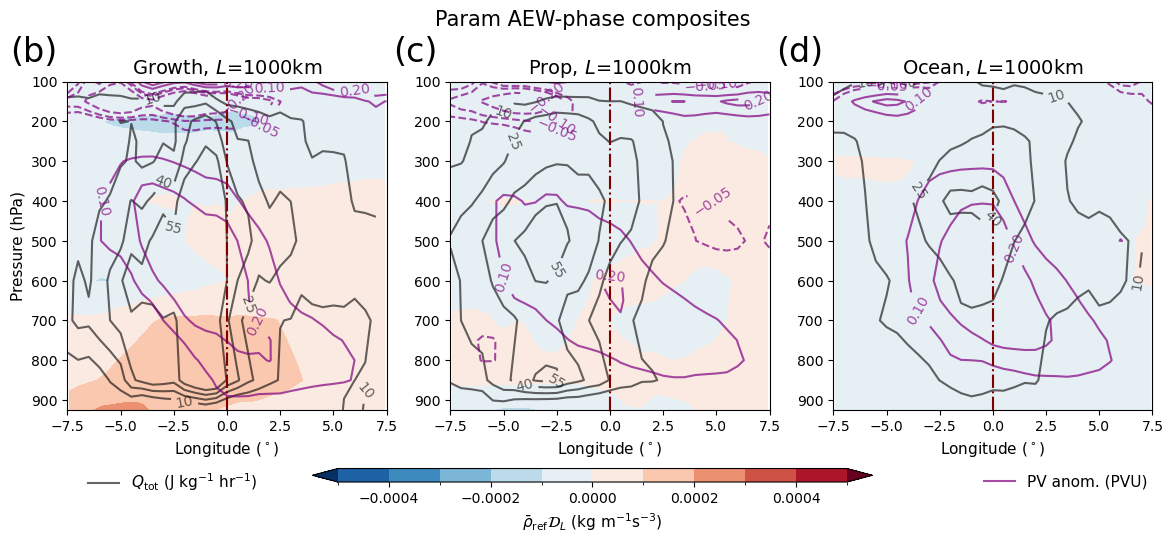

In [50]:
phases=["growth","prop","ocean"]
sim="ctc_gal9"
scales=[500]
for j, scale in enumerate(scales):
    fig,axes=plt.subplots(1,3,figsize=(14,4.5))
    for i, phase in enumerate(phases):
        ax=axes[i]
        data=(data_dict[sim+"-density_ref"]*comp_dict[sim+"-"+phase+"_isetQ"].Dl_u_mean.sel(length_scale=scale)).sel(lat=slice(-3.5,3.5)).mean(dim="lat")
        Cb=data.plot.contourf(ax=ax,vmax=0.0005,levels=11,extend="both",add_colorbar=False)
        cQ=(3600*comp_dict[sim+"-"+phase+"_isetQ"].Q_tot_mean).sel(latitude=slice(-3.5,3.5)).mean(dim="latitude"
                                                    ).plot.contour(ax=ax,levels=np.arange(10,56,15),colors="k",alpha=0.6)
        ax.clabel(cQ)
        cPV=(1e6*comp_dict[sim+"-"+phase+"_dynamics"].pv_anom_mean).sel(latitude=slice(-1.5,1.5)).mean(dim="latitude"
                                                    ).plot.contour(ax=ax,levels=[-0.2,-0.1,-0.05,0.1,0.2],colors="Purple",alpha=0.7)
        ax.clabel(cPV)
        #data.plot.contourf(ax=ax,colors="none",levels=[0,0.05],hatches=[".",""],add_colorbar=False)
        ax.set_ylim([925,100])
        ax.set_title(f"{phase.capitalize()}, $L$={2*scale:.0f}km",fontsize=14)
        ax.axvline(0,ls="-.",color="maroon")
        ax.set_ylabel("")
        ax.set_xlabel(r"Longitude ($^\circ$)",fontsize=11)
        ax.text(-0.18,1.06,"("+string.ascii_lowercase[i+1]+")",fontsize=24,transform=axes[i].transAxes)
    axes[0].set_ylabel("Pressure (hPa)",fontsize=11)

    fig.subplots_adjust(bottom=0.15)
    cax = fig.add_axes([0.3,-0.01,0.4,0.03])
    clb=fig.colorbar(Cb, cax = cax, orientation = "horizontal", extend = "both").set_label(label=r"$\bar\rho_{\rm ref}\mathcal{D}_L$ (kg m$^{-1}$s$^{-3}$)",fontsize=11)

    
    fig.legend(handles=[Line2D([],[], color="k", alpha=0.6, label=r"$Q_{\rm tot}$ (J kg$^{-1}$ hr$^{-1}$)")], 
                  fontsize=11, bbox_to_anchor=(0.13,-0.01), frameon=False ,loc="center left")
    fig.legend(handles=[Line2D([],[], color="Purple", alpha=0.7, label="PV anom. (PVU)")], 
                  fontsize=11, bbox_to_anchor=(0.77,-0.01), frameon=False ,loc="center left")
    fig.suptitle("Param AEW-phase composites",fontsize=15,y=1.04)
    fig.savefig(f"Figures/Param_AEW_lossett_composites.png",dpi=400,bbox_inches="tight",facecolor="white")

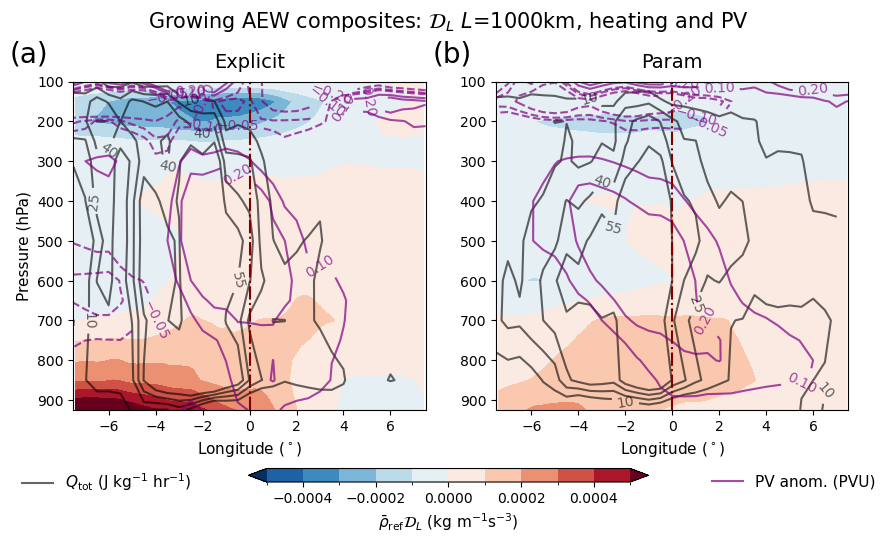

In [51]:
fig,axes=plt.subplots(1,2,figsize=(10,4.5))
phase,scale="growth",500
for i, sim in enumerate(["ctc_ral3","ctc_gal9"]):
    ax=axes[i]
    data=(data_dict[sim+"-density_ref"]*comp_dict[sim+"-"+phase+"_isetQ"].Dl_u_mean.sel(length_scale=scale)).sel(lat=slice(-3.5,3.5)).mean(dim="lat")
    Cb=data.plot.contourf(ax=ax,vmax=0.0005,levels=11,extend="both",add_colorbar=False)
    cQ=(3600*comp_dict[sim+"-"+phase+"_isetQ"].Q_tot_mean).sel(latitude=slice(-3.5,3.5)).mean(dim="latitude"
                                                ).plot.contour(ax=ax,levels=np.arange(10,56,15),colors="k",alpha=0.6)
    ax.clabel(cQ)
    cPV=(1e6*comp_dict[sim+"-"+phase+"_dynamics"].pv_anom_mean).sel(latitude=slice(-1.5,1.5)).mean(dim="latitude"
                                                ).plot.contour(ax=ax,levels=[-0.2,-0.1,-0.05,0.1,0.2],colors="Purple",alpha=0.7)
    ax.clabel(cPV)
    #data.plot.contourf(ax=ax,colors="none",levels=[0,0.05],hatches=[".",""],add_colorbar=False)
    ax.set_ylim([925,100])
    ax.set_title(f"{phase.capitalize()}, $L$={2*scale:.0f}km",fontsize=14)
    ax.axvline(0,ls="-.",color="maroon")
    ax.set_ylabel("")
    ax.set_xlabel(r"Longitude ($^\circ$)",fontsize=11)
    ax.set_title(data_dict[sim+"-tstr"],fontsize=14,pad=10)
    ax.text(-0.18,1.06,"("+string.ascii_lowercase[i]+")",fontsize=20,transform=axes[i].transAxes)
axes[0].set_ylabel("Pressure (hPa)",fontsize=11)

fig.subplots_adjust(bottom=0.15)
cax = fig.add_axes([0.3,-0.01,0.4,0.03])
clb=fig.colorbar(Cb, cax = cax, orientation = "horizontal", extend = "both").set_label(label=r"$\bar\rho_{\rm ref}\mathcal{D}_L$ (kg m$^{-1}$s$^{-3}$)",fontsize=11)


fig.legend(handles=[Line2D([],[], color="k", alpha=0.6, label=r"$Q_{\rm tot}$ (J kg$^{-1}$ hr$^{-1}$)")], 
              fontsize=11, bbox_to_anchor=(0.06,-0.01), frameon=False ,loc="center left")
fig.legend(handles=[Line2D([],[], color="Purple", alpha=0.7, label="PV anom. (PVU)")], 
              fontsize=11, bbox_to_anchor=(0.75,-0.01), frameon=False ,loc="center left")
fig.suptitle(r"Growing AEW composites: $\mathcal{D}_L$ $L$=1000km, heating and PV",fontsize=15,y=1.04)
fig.savefig(f"Figures/Growing_AEW_mm_composites.png",dpi=400,bbox_inches="tight",facecolor="white")

FIG 10

In [52]:
for sim in sims:
    fstr=data_dict[sim+"-fstr"]
    data_dict[sim+"-dynamics"]=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_{fstr}_dynamics_0p5deg.nc")
    data_dict[sim+"-thermo"]=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_{fstr}_thermo_0p5deg.nc")
    data_dict[sim+"-filt"]=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_{fstr}_0p5deg_3-5d_filter_EAtl.nc")

    zm = data_dict[sim+"-filt"].mean(dim="longitude")
    data_dict[sim+"-filt_pert"] = data_dict[sim+"-filt"] - zm

In [53]:
pressure=data_dict[sim+"-dynamics"].pressure.values

In [54]:
for sim in sims:
    data_dict[sim+"-eke"] = 1/2 * (data_dict[sim+"-filt_pert"].x_wind**2 + data_dict[sim+"-filt_pert"].y_wind**2)
    data_dict[sim+"-cPK"] = -(8.31/pressure[1:None,None,None,None]) * data_dict[sim+"-filt_pert"].pressure_tendency * data_dict[sim+"-filt_pert"].air_temperature
    temp=data_dict[sim+"-dynamics"].x_wind.sel(latitude=slice(-0.5,26))
    dx,dy=mpcalc.lat_lon_grid_deltas(temp.longitude, temp.latitude)
    #data_dict[sim+"-filt"]=data_data_dict[sim+"-filt"].sel(latitude=slice(
    up=data_dict[sim+"-filt_pert"].x_wind.sel(longitude=slice(-15,20))
    u=data_dict[sim+"-filt"].x_wind.sel(longitude=slice(-15,20))
    vp=data_dict[sim+"-filt_pert"].y_wind.sel(longitude=slice(-15,20))
    v=data_dict[sim+"-filt"].y_wind.sel(longitude=slice(-15,20))
    wp=data_dict[sim+"-filt_pert"].pressure_tendency.sel(longitude=slice(-15,20))
    
    data_dict[sim+"-cK1"] = - (up * vp).mean(dim="longitude") * u.mean(dim="longitude").differentiate("latitude") / dy.magnitude[:,0][None,None,:]
    data_dict[sim+"-cK2"] = - (up * wp).mean(dim="longitude") * -1 * u.mean(dim="longitude").differentiate("pressure")/100.
    data_dict[sim+"-cK3"] = - (vp * vp).mean(dim="longitude") * v.mean(dim="longitude").differentiate("latitude") / dy.magnitude[:,0][None,None,:]
    data_dict[sim+"-cK4"] = - (vp * wp).mean(dim="longitude") * -1 * v.mean(dim="longitude").differentiate("pressure")/100.

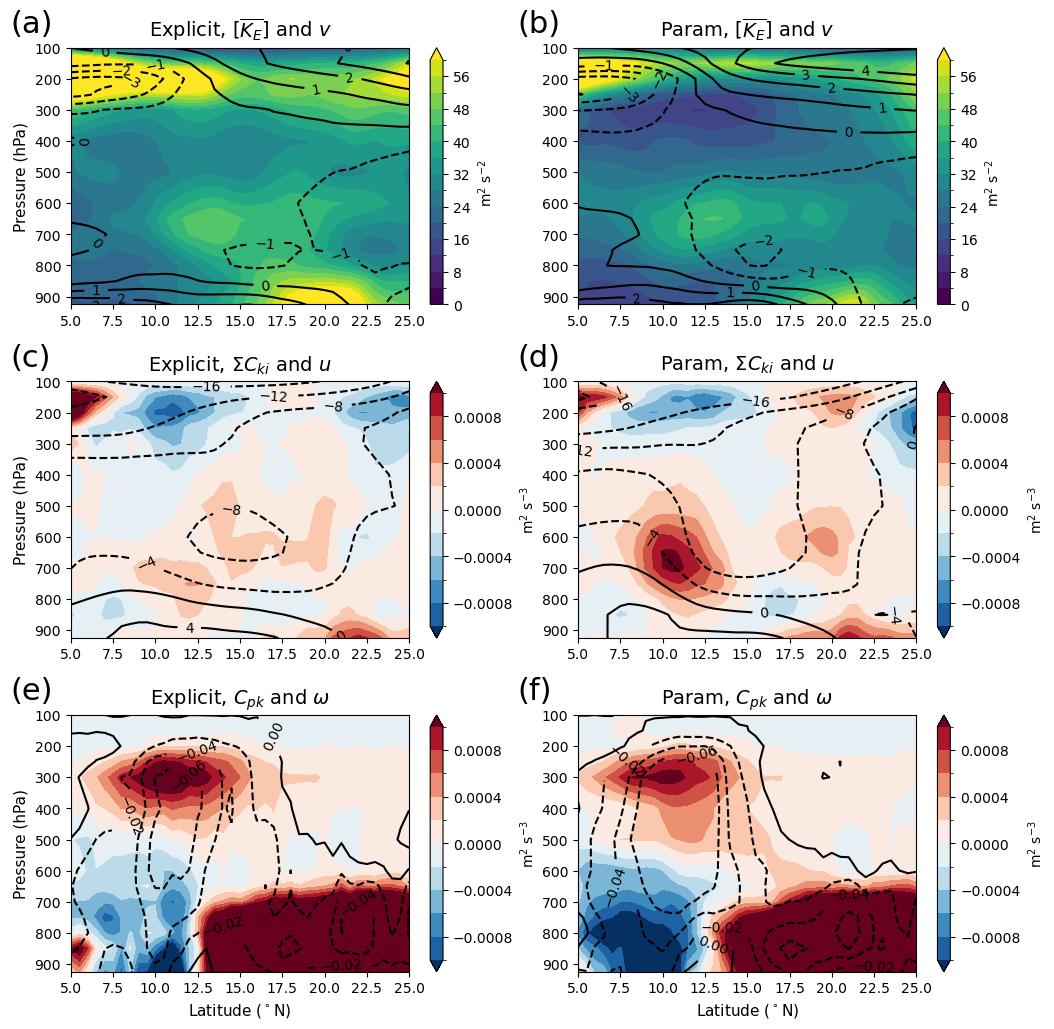

In [55]:
fig,axes=plt.subplots(3,2,figsize=(12,12),gridspec_kw={"hspace":0.3})

for i, sim in enumerate(sims[::-1]):
    data_dict[sim+"-eke"].sel(longitude=slice(-15,20)).mean(dim=["longitude","time"]).plot.contourf(ax=axes[0,i],vmax=60,levels=16,vmin=0,
                                                                       extend="max",shrink=0.6,cbar_kwargs={"label":"m$^2$ s$^{-2}$"})
    Cu=data_dict[sim+"-filt"].y_wind.sel(longitude=slice(-15,20),latitude=slice(5,25)).mean(
                    dim=["time","longitude"]).plot.contour(ax=axes[0,i],levels=np.arange(-4,5),colors="k")
    axes[0,i].clabel(Cu)
    axes[0,i].set_title(data_dict[sim+"-tstr"]+r", $[\overline{K_E}]$ and $v$",fontsize=14, pad=8)
    axes[0,i].text(-0.18,1.06,"("+string.ascii_lowercase[i]+")",fontsize=22,transform=axes[0,i].transAxes)

    (data_dict[sim+"-cK1"]+data_dict[sim+"-cK2"]+data_dict[sim+"-cK3"]+data_dict[sim+"-cK4"]).mean(dim=["time"]).plot.contourf(
                                    ax=axes[1,i],vmax=1e-3,levels=11,extend="both",shrink=0.6,cbar_kwargs={"label":"m$^2$ s$^{-3}$"})
    Cu=data_dict[sim+"-filt"].x_wind.sel(longitude=slice(-15,20),latitude=slice(5,25)).mean(
                    dim=["time","longitude"]).plot.contour(ax=axes[1,i],levels=np.arange(-16,17,4),colors="k")
    axes[1,i].clabel(Cu)
    axes[1,i].set_title(data_dict[sim+"-tstr"]+r", $\Sigma C_{ki}$ and $u$",fontsize=14,pad=8)
    axes[1,i].text(-0.18,1.06,"("+string.ascii_lowercase[2+i]+")",fontsize=22,transform=axes[1,i].transAxes)

    data_dict[sim+"-cPK"].mean(dim=["longitude","time"]).plot.contourf(ax=axes[2,i],vmax=1e-3,levels=11,
                                                                       extend="both",shrink=0.6,cbar_kwargs={"label":"m$^2$ s$^{-3}$"})
    Cu=(data_dict[sim+"-filt"]).pressure_tendency.sel(longitude=slice(-15,20)).mean(
                            dim=["time","longitude"]).plot.contour(ax=axes[2,i],levels=np.arange(-0.06,0.07,0.02),colors="k")
    axes[2,i].clabel(Cu)
    axes[2,i].set_title(data_dict[sim+"-tstr"]+r", $C_{pk}$ and $\omega$",fontsize=14,pad=8)
    axes[2,i].text(-0.18,1.06,"("+string.ascii_lowercase[4+i]+")",fontsize=22,transform=axes[2,i].transAxes)

for i,ax in enumerate(axes.flatten()):
    ax.set_ylim([925,100])
    ax.set_xlim([5,25])
    ax.set_xlabel("")
    ax.set_ylabel("")
    if i>3:
        ax.set_xlabel(r"Latitude ($^\circ$N)",fontsize=11)
    if i%2==0:
        ax.set_ylabel("Pressure (hPa)",fontsize=11)
fig.savefig(f"Figures/Energetics_means.png",dpi=400,bbox_inches="tight",facecolor="white")

FIG 8

In [56]:
for sim in sims:
    tm = data_dict[sim+"-filt"].mean(dim="longitude")
    data_dict[sim+"-filt_pert_tm"] = data_dict[sim+"-filt"] - tm

In [57]:
sim="ctc_ral3"
eke=1/2 * (data_dict[sim+"-filt_pert_tm"].x_wind**2 + data_dict[sim+"-filt_pert_tm"].y_wind**2)
deke_dt = eke.differentiate("time")

In [58]:
tm = data_dict[sim+"-filt"].mean(dim="longitude")

In [59]:
Deke_Dt = deke_dt + (
                mpcalc.advection(eke,u=tm.x_wind.metpy.quantify(),v=tm.y_wind.metpy.quantify()
                                ).metpy.dequantify()
                + mpcalc.advection(eke,u=data_dict[sim+"-filt_pert_tm"].x_wind.metpy.quantify(),v=data_dict[sim+"-filt_pert_tm"].y_wind.metpy.quantify()
                                  ).metpy.dequantify())

In [60]:
aew_Deke_Dt=(data_dict[sim+"-density_ref"].sel(pressure=slice(600,750))[::-1]*Deke_Dt.sel(pressure=slice(750,600))).mean(dim="pressure")

In [61]:
case_aew=data_dict[sim+"-aew_tracks"].sel(system=7)
case_aew=case_aew.where((case_aew.AEW_strength>0) & (case_aew.AEW_lon<30) & (case_aew.AEW_lon>-30)
                        ,drop=True)

In [62]:
def haversine(lon1, lat1, lon2, lat2):
    """
    Calculate the great circle distance in kilometers between two points 
    on the earth (specified in decimal degrees)
    """
    # convert decimal degrees to radians 
    lon1, lat1, lon2, lat2 = map(np.deg2rad, [lon1, lat1, lon2, lat2])

    # haversine formula 
    dlon = lon2 - lon1 
    dlat = lat2 - lat1 
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.sin(np.sqrt(a)) 
    r = 6371 # Radius of earth in kilometers. Use 3956 for miles. Determines return value units.
    return c * r

In [63]:
def get_corr_str(data1,data2):
    pearsonr=stats.pearsonr(data1,data2)
    if pearsonr.pvalue<0.05:
        return f"r={pearsonr.statistic:.2f} ({pearsonr.pvalue:.2f})"
    else:
        return ""

0.0012033811712950967 -0.0008011673926375806 -0.00026950339088216424
0.0012033811712950967 -0.0006167525425553322 -0.0002826976706273854
0.0012033811712950967 -0.0002889924217015505 -0.00029890122823417187


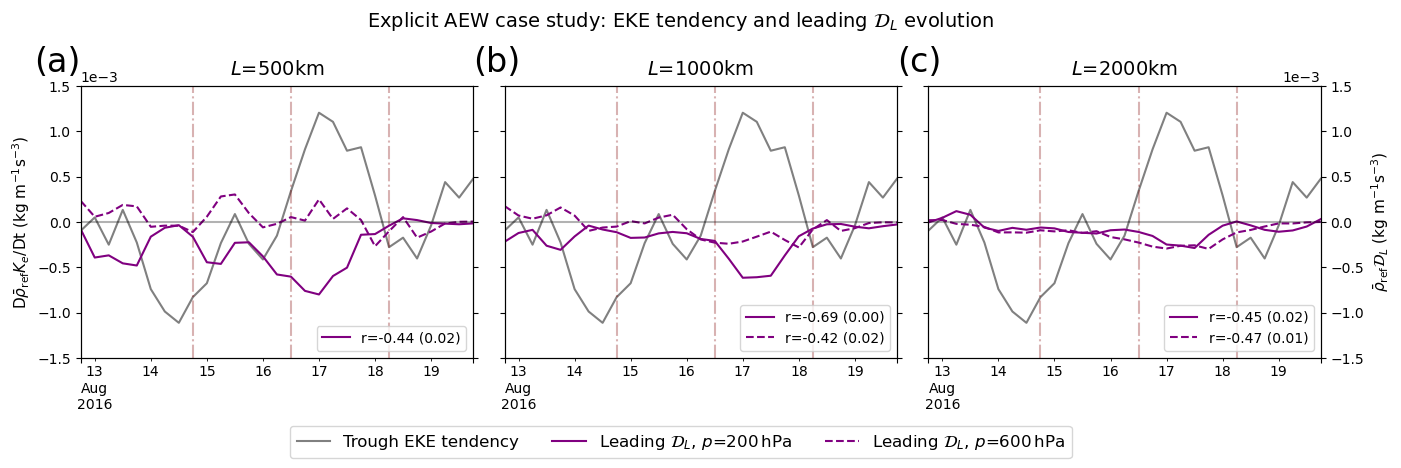

In [64]:
fig,axes=plt.subplots(1,3,figsize=(16,4),gridspec_kw={"wspace":0.08})

for j,scale in enumerate([250,500,1000]):
    eke_vals,lossett200_vals,lossett600_vals=[],[],[]
    for i, tstamp in enumerate(case_aew.time):
        wave_eke=Deke_Dt.sel(time=tstamp)
        wave_lossett200,wave_lossett600=data_dict[sim+"-lossett_p200"].Dl_u.sel(time=tstamp,length_scale=scale*1000),data_dict[sim+"-lossett_p600"].Dl_u.sel(time=tstamp,length_scale=scale*1000)
        dists = xr.apply_ufunc(haversine,wave_eke.longitude,wave_eke.latitude,case_aew.AEW_lon.values[i],case_aew.AEW_lat.values[i])
        dists = (dists/dists).where(dists<=300).fillna(0).T
        eke_vals.append(float(wave_eke.where(dists!=0).mean()))
        
        dists = xr.apply_ufunc(haversine,wave_lossett200.longitude,wave_lossett200.latitude,case_aew.AEW_lon.values[i] - 2,case_aew.AEW_lat.values[i])
        dists = (dists/dists).where(dists<=300).fillna(0).T
        lossett200_vals.append(float(data_dict[sim+"-density_ref"].sel(pressure=200)*wave_lossett200.where(dists!=0).mean()))
        lossett600_vals.append(float(data_dict[sim+"-density_ref"].sel(pressure=600)*wave_lossett600.where(dists!=0).mean()))

    ax=axes[j]
    pd.Series(eke_vals,case_aew.time).plot(ax=ax,color="grey")
    ax1=ax.twinx()
    rstr=get_corr_str(eke_vals,lossett200_vals)
    pd.Series(lossett200_vals,case_aew.time).plot(ax=ax1,color="purple",label=rstr)
    rstr=get_corr_str(eke_vals,lossett600_vals)
    pd.Series(lossett600_vals,case_aew.time).plot(ax=ax1,color="purple",ls="--",label=rstr)
    #pearsonr200=stats.pearsonr(eke_vals,lossett200_vals)
    #pearsonr600=stats.pearsonr(eke_vals,lossett600_vals)
    ax.set_title(f"$L$={2*scale:.0f}km",fontsize=14,pad=8)#; r={pearsonr200.statistic:.2f}/{pearsonr600.statistic:.2f} ({pearsonr200.pvalue:.2f}/{pearsonr600.pvalue:.2f})")
    ax1.legend(loc="lower right")
    ax.ticklabel_format(scilimits=[-2,3],axis="y")
    ax1.ticklabel_format(scilimits=[-2,3],axis="y")
    ax1.set_ylim([-1.5e-3,1.5e-3])
    ax.set_ylim([-1.5e-3,1.5e-3])
    ax1.axhline(0,color="k",alpha=0.3)
    ax.axvline("2016-08-14 18:00",color="maroon",ls="-.",alpha=0.3)
    ax.axvline("2016-08-16 12:00",color="maroon",ls="-.",alpha=0.3)
    ax.axvline("2016-08-18 06:00",color="maroon",ls="-.",alpha=0.3)
    if j>0:
        ax.set_yticklabels("")
        ax.text(-0.08,1.05,f"({string.ascii_lowercase[j]})",fontsize=24,transform=ax.transAxes)
    if j<2:
        ax1.set_yticklabels("")
    print(max(eke_vals),min(lossett200_vals),min(lossett600_vals))
axes[0].set_ylabel(r"D$\bar\rho_{\rm ref}K_e$/Dt (kg m$^{-1}$s$^{-3}$)",fontsize=11)
axes[0].text(-0.12,1.05,f"(a)",fontsize=24,transform=axes[0].transAxes)
ax1.set_ylabel(r"$\bar\rho_{\rm ref}\mathcal{D}_L$ (kg m$^{-1}$s$^{-3}$)",fontsize=11)

legend_elements = [Line2D([],[],color="grey", marker="", label="Trough EKE tendency"),
                   Line2D([],[],color="purple", marker="", label=r"Leading $\mathcal{D}_L$, $p$=200$\,$hPa"),
                   Line2D([],[],color="purple", ls="--", marker="", label=r"Leading $\mathcal{D}_L$, $p$=600$\,$hPa")]
fig.subplots_adjust(bottom=0.2)
fig.legend(handles=legend_elements, ncol=3, bbox_to_anchor=(0.5,-0.01), loc="center",fontsize=12)
fig.suptitle(r"Explicit AEW case study: EKE tendency and leading $\mathcal{D}_L$ evolution",fontsize=14,y=1.07) 
fig.savefig("Figures/Explicit_case_study_energetics.png",dpi=400,bbox_inches="tight",facecolor="white")

SUPPLEMENTARY FIGURES

FIG S1

In [65]:
import matplotlib.ticker as mticker

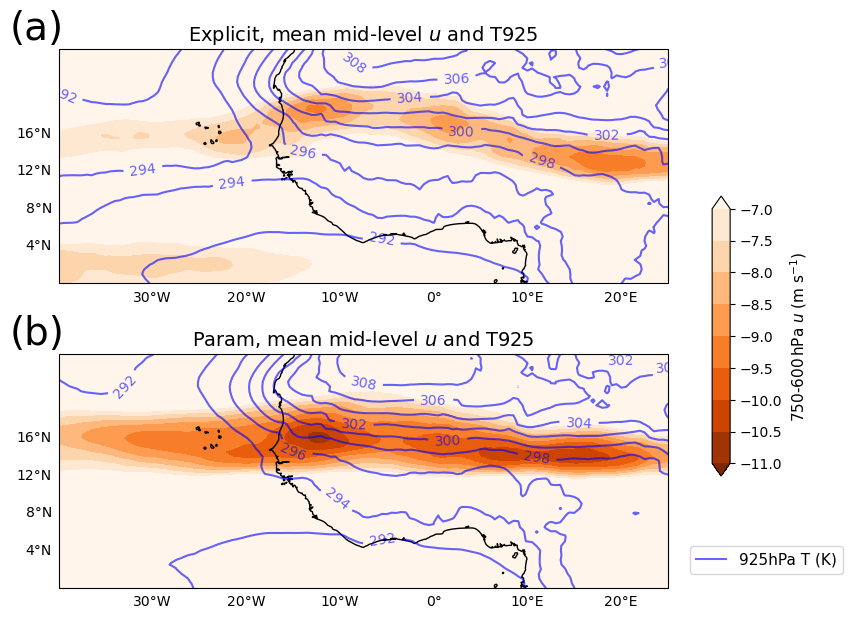

In [66]:
# Paper version - 1 column

fig,axes=plt.subplots(2,1,figsize=(9,7),subplot_kw=dict(projection=ccrs.PlateCarree()),gridspec_kw={"hspace":0.3})

axes=axes.flatten()
for i,sim in enumerate(sims[::-1]):
    ax=axes[i]
    u=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_{data_dict[sim+"-fstr"]}_dynamics_0p5deg.nc").x_wind.sel(
                        latitude=slice(0,25),longitude=slice(-45,35),pressure=[600,650,700,750]).mean(dim=["time","pressure"])
    t=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_{data_dict[sim+"-fstr"]}_thermo_0p5deg.nc").air_temperature.sel(
                        latitude=slice(0,25),longitude=slice(-45,35),pressure=925).mean(dim=["time"])
    
    cb=u.plot.contourf(ax=ax,levels=np.arange(-11,-6.5,0.5),cmap="Oranges_r",add_colorbar=False,extend="both")
    Ct=t.plot.contour(ax=ax,levels=np.arange(290,312,2),colors="blue",alpha=0.6)
    ax.clabel(Ct)
    ax.set_title(data_dict[sim+"-tstr"]+", mean mid-level $u$ and T925",fontsize=14)
    
    ax.coastlines()
    gl=ax.gridlines(draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlines = False
    gl.ylines = False
    gl.ylocator = mticker.FixedLocator([4,8,12,16])
    #ax.set_ylim([1.25,19.25])
    ax.set_xlim([-40,25])
    ax.text(-0.08,1.04,f"({string.ascii_lowercase[i]})",fontsize=28,transform=ax.transAxes)
    
fig.legend(handles=[Line2D([],[],color="blue", alpha=0.6, marker="", label='925hPa T (K)')], 
               fontsize='11', ncols=3, loc="center", bbox_to_anchor=(0.96,0.15))
#cax = fig.add_axes([0.6,0.27,0.25,0.015])
#clb=fig.colorbar(cb, cax = cax, orientation = "horizontal", extend = "both").set_label(label=r"Vortex number",fontsize=11)
cax = fig.add_axes([0.9,0.27,0.02,0.4])
clb=fig.colorbar(cb, cax = cax, orientation = "vertical", extend = "both").set_label(label=r"750-600$\,$hPa $u$ (m s$^{-1}$)",fontsize=11)
fig.savefig("Figures/WAM_mean_states-winds.png",dpi=200,bbox_inches="tight",facecolor="white")

FIG S2

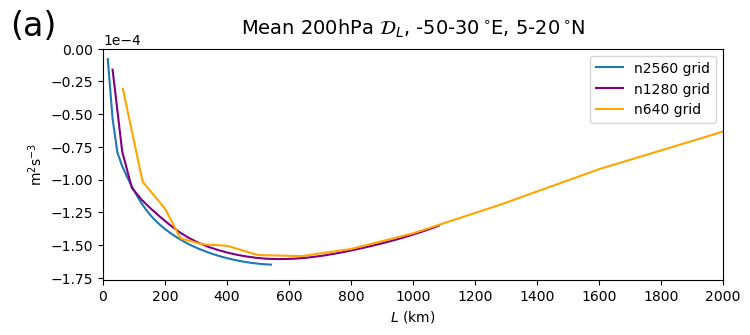

In [67]:
dsF20=xr.open_dataset("/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_CTC_RAL3p2_mean_EAtl_losset_n640-first20d.nc")
dsNat=xr.open_dataset("/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_CTC_RAL3p2_mean_EAtl_losset_n2560-first20d.nc")
ds1280F20=xr.open_dataset("/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_CTC_RAL3p2_mean_EAtl_losset_n1280_p200-first20d.nc")

fig,ax=plt.subplots(figsize=(8,3))
dsNat.Dl_u.sel(longitude=slice(-50,30),latitude=slice(5,20),pressure=200).mean(dim=["latitude","longitude"]).plot(label="n2560 grid")
ds1280F20.Dl_u.sel(longitude=slice(-50,30),latitude=slice(5,20),pressure=200).mean(dim=["latitude","longitude"]).plot(color="purple",label="n1280 grid")
dsF20.Dl_u.sel(longitude=slice(-50,30),latitude=slice(5,20),pressure=200).mean(dim=["latitude","longitude"]).plot(color="orange",label="n640 grid")
ax.legend()
ax.set_xlim([0,1e6])
ax.set_xticks(np.arange(0,1.1e6,1e5))
ax.set_xticklabels([f"{2*l/1000:.0f}" for l in np.arange(0,1.1e6,1e5)])
ax.set_xlabel("$L$ (km)")
ax.set_title(r"Mean 200hPa $\mathcal{D}_L$, -50-30$^\circ\!$E, 5-20$^\circ\!$N",fontsize=14,pad=10)
ax.set_ylim([None,0])
ax.set_ylabel("m$^2$s$^{-3}$")
ax.ticklabel_format(scilimits=[-2,3],axis="y")
ax.text(-150000,1e-5,"(a)",fontsize=24)
fig.savefig(f"Figures/SuppFig_lossett_grid_comparison.png",dpi=400,bbox_inches="tight",facecolor="white")

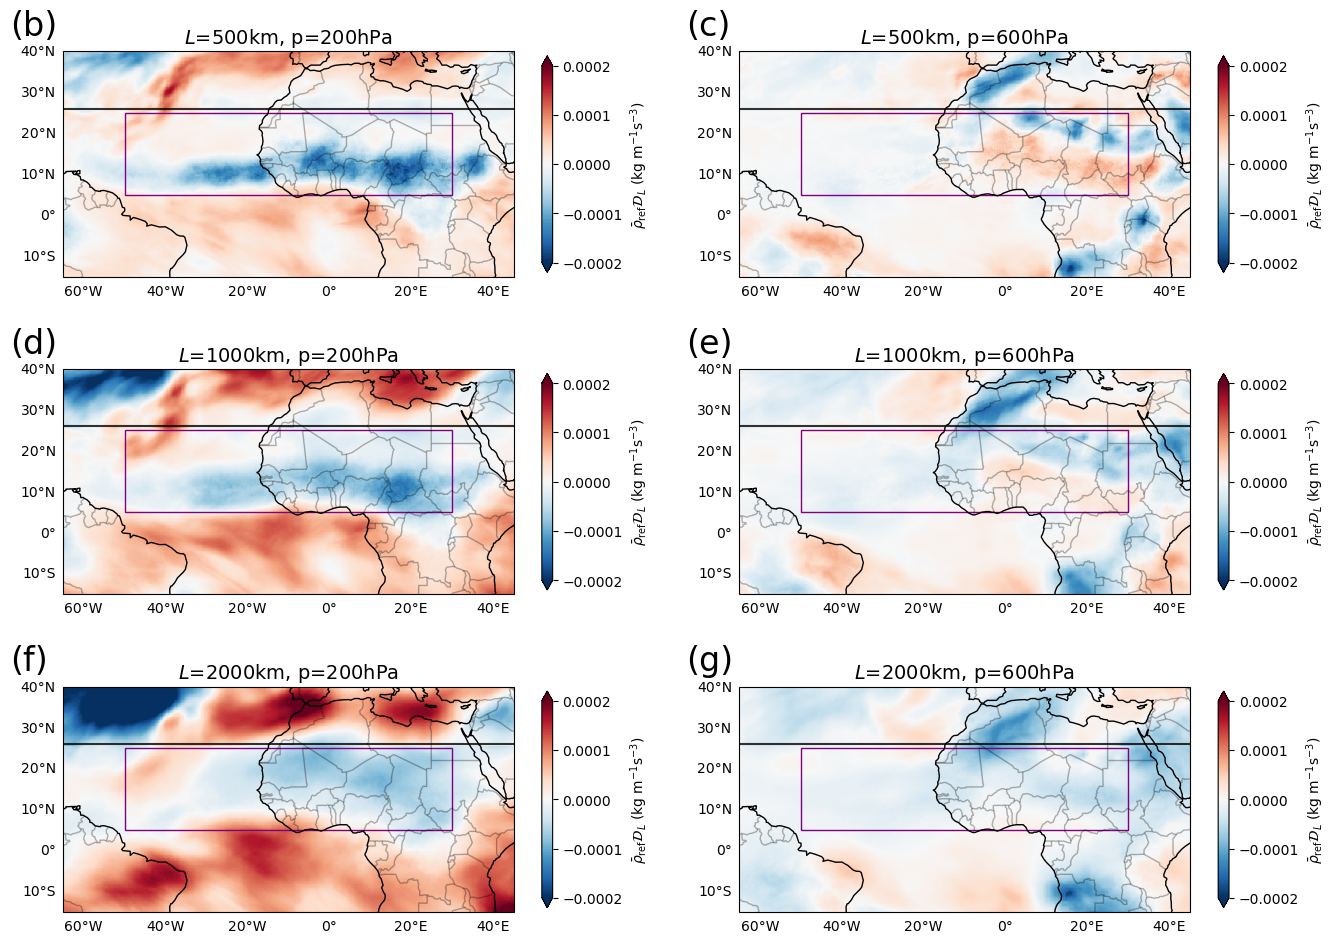

In [68]:
fig,axes=plt.subplots(3,2,figsize=(16,12),subplot_kw=dict(projection=ccrs.PlateCarree()),gridspec_kw={"hspace":0.1})
axes=axes.flatten()

ds=xr.open_dataset("/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_CTC_RAL3p2_mean_EAtl_losset_n640ext.nc")
rho200,rho600=data_dict["ctc_ral3-density_ref"].sel(pressure=200),data_dict["ctc_ral3-density_ref"].sel(pressure=600)

(rho200*ds.sel(length_scale=250000,pressure=200)).Dl_u.plot(ax=axes[0],vmax=0.0002,extend="both",cbar_kwargs={"shrink":0.75,"label":r"$\bar\rho_{\rm ref}\mathcal{D}_L$ (kg m$^{-1}$s$^{-3}$)"})
axes[0].set_title("$L$=500km, p=200hPa",fontsize=14)
(rho600*ds.sel(length_scale=250000,pressure=600)).Dl_u.plot(ax=axes[1],vmax=0.0002,extend="both",cbar_kwargs={"shrink":0.75,"label":r"$\bar\rho_{\rm ref}\mathcal{D}_L$ (kg m$^{-1}$s$^{-3}$)"})
axes[1].set_title("$L$=500km, p=600hPa",fontsize=14)
(rho200*ds.sel(length_scale=500000,pressure=200)).Dl_u.plot(ax=axes[2],vmax=0.0002,extend="both",cbar_kwargs={"shrink":0.75,"label":r"$\bar\rho_{\rm ref}\mathcal{D}_L$ (kg m$^{-1}$s$^{-3}$)"})
axes[2].set_title("$L$=1000km, p=200hPa",fontsize=14)
(rho600*ds.sel(length_scale=500000,pressure=600)).Dl_u.plot(ax=axes[3],vmax=0.0002,extend="both",cbar_kwargs={"shrink":0.75,"label":r"$\bar\rho_{\rm ref}\mathcal{D}_L$ (kg m$^{-1}$s$^{-3}$)"})
axes[3].set_title("$L$=1000km, p=600hPa",fontsize=14)
(rho200*ds.sel(length_scale=1000000,pressure=200)).Dl_u.plot(ax=axes[4],vmax=0.0002,extend="both",cbar_kwargs={"shrink":0.75,"label":r"$\bar\rho_{\rm ref}\mathcal{D}_L$ (kg m$^{-1}$s$^{-3}$)"})
axes[4].set_title("$L$=2000km, p=200hPa",fontsize=14)
(rho600*ds.sel(length_scale=1000000,pressure=600)).Dl_u.plot(ax=axes[5],vmax=0.0002,extend="both",cbar_kwargs={"shrink":0.75,"label":r"$\bar\rho_{\rm ref}\mathcal{D}_L$ (kg m$^{-1}$s$^{-3}$)"})
axes[5].set_title("$L$=2000km, p=600hPa",fontsize=14)

for i, ax in enumerate(axes):
    ax.coastlines()
    ax.axhline(26,color="k",alpha=0.8)
    ax.add_feature(cfeature.BORDERS,alpha=0.3)
    gl=ax.gridlines(draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    gl.ylines = False
    gl.xlines = False
    ax.add_patch(mpatch.Rectangle((-50,5),80,20,fill=False,edgecolor="purple",transform=ccrs.PlateCarree()))
    ax.text(-78,44,f"({string.ascii_lowercase[i+1]})",fontsize=24)
fig.savefig(f"Figures/SuppFig_Explicit_lossett_spatial_means.png",dpi=400,bbox_inches="tight",facecolor="white")

FIG S3

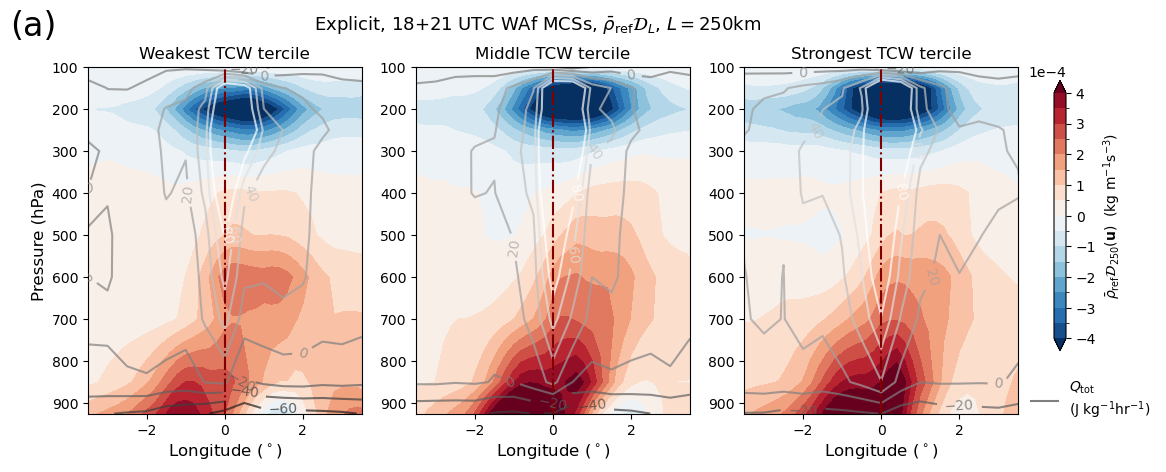

In [69]:
scale=250
ds=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/composites/DY2_CTC_RAL3p2_MCS_tcwTer_n640_L={scale}_isetQ_0p2deg.nc")

fig,axes=plt.subplots(1,3,figsize=(12,4.5))
vmax=0.0004
tlabs=["Weakest","Middle","Strongest"]
for i, tercile in enumerate(["t1","t2","t3"]):
    rho_ref=data_dict["ctc_ral3-density_ref"]
    Cb=(rho_ref*ds["Dl_"+tercile].sel(lat=slice(-1.5,1.5))).mean(dim="lat").plot.contourf(ax=axes[i],levels=17,vmax=vmax,extend="both",add_colorbar=False)
    cQ=(3600*ds["Qtot_"+tercile]).sel(latitude=slice(-1.5,1.5)).mean(dim="latitude").plot.contour(ax=axes[i],levels=np.arange(-80,91,20),cmap="grey",alpha=0.7)
    axes[i].clabel(cQ)    
    axes[i].set_ylim([925,100])
    axes[i].set_xlim([-3.5,3.5])
    axes[i].set_xlabel(r"Longitude ($^\circ$)",fontsize=12)
    axes[i].set_ylabel("")
    axes[i].set_title(tlabs[i]+" TCW tercile",fontsize=12)
    axes[i].axvline(0,color="maroon",ls="-.")
axes[0].set_ylabel("Pressure (hPa)",fontsize=12)
fig.suptitle(r"Explicit, 18+21 UTC WAf MCSs, $\bar\rho_{\rm ref}\mathcal{D}_L$, $L=$%skm"%scale,y=1,fontsize=13)

cax = fig.add_axes([0.93,0.25,0.01,0.6])
cbar=fig.colorbar(Cb, cax = cax, orientation = "vertical", extend = "both")#
#cbar=clb.colorbar
cbar.formatter.set_powerlimits((0, 0)) 
cbar.update_ticks()
cbar.set_label(label=r"$\bar\rho_{\rm ref}\mathcal{D}_{%s}(\mathbf{u})$  (kg m$^{-1}$s$^{-3}$)"%scale,fontsize=10)
fig.legend(handles=[Line2D([],[], color="Grey", label=r"$Q_{\rm tot}$"+"\n(J kg$^{-1}$hr$^{-1}$)")], 
              fontsize=10, bbox_to_anchor=(0.9,0.14), frameon=False ,loc="center left")
fig.text(0.06,0.95,"(a)",fontsize=24)
fig.savefig(f"Figures/MCS_transfer_tcw_composites.png",dpi=400,bbox_inches="tight",facecolor="white")

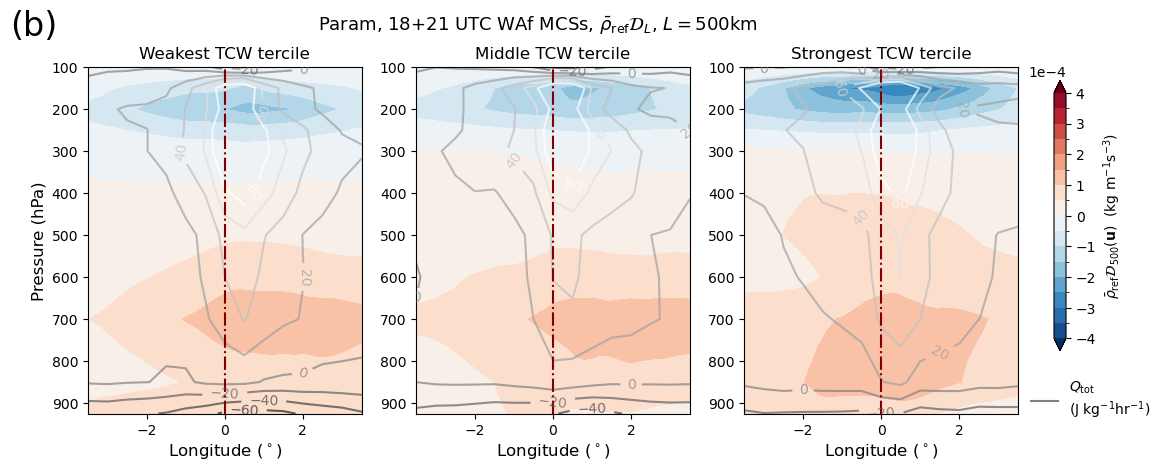

In [70]:
scale=500
ds=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/composites/DY2_CTC_GAL9_MCS_tcwTer_n640_L={scale}_isetQ_0p2deg.nc")

fig,axes=plt.subplots(1,3,figsize=(12,4.5))
vmax=0.0004
tlabs=["Weakest","Middle","Strongest"]
for i, tercile in enumerate(["t1","t2","t3"]):
    rho_ref=data_dict["ctc_gal9-density_ref"]
    Cb=(rho_ref*ds["Dl_"+tercile].sel(lat=slice(-1.5,1.5))).mean(dim="lat").plot.contourf(ax=axes[i],levels=17,vmax=vmax,extend="both",add_colorbar=False)
    cQ=(3600*ds["Qtot_"+tercile]).sel(latitude=slice(-1.5,1.5)).mean(dim="latitude").plot.contour(ax=axes[i],levels=np.arange(-80,91,20),cmap="grey",alpha=0.7)
    axes[i].clabel(cQ)    
    axes[i].set_ylim([925,100])
    axes[i].set_xlim([-3.5,3.5])
    axes[i].set_xlabel(r"Longitude ($^\circ$)",fontsize=12)
    axes[i].set_ylabel("")
    axes[i].set_title(tlabs[i]+" TCW tercile",fontsize=12)
    axes[i].axvline(0,color="maroon",ls="-.")
axes[0].set_ylabel("Pressure (hPa)",fontsize=12)
fig.suptitle(r"Param, 18+21 UTC WAf MCSs, $\bar\rho_{\rm ref}\mathcal{D}_L$, $L=$%skm"%scale,y=1,fontsize=13)

cax = fig.add_axes([0.93,0.25,0.01,0.6])
cbar=fig.colorbar(Cb, cax = cax, orientation = "vertical", extend = "both")#
#cbar=clb.colorbar
cbar.formatter.set_powerlimits((0, 0)) 
cbar.update_ticks()
cbar.set_label(label=r"$\bar\rho_{\rm ref}\mathcal{D}_{%s}(\mathbf{u})$  (kg m$^{-1}$s$^{-3}$)"%scale,fontsize=10)
fig.legend(handles=[Line2D([],[], color="Grey", label=r"$Q_{\rm tot}$"+"\n(J kg$^{-1}$hr$^{-1}$)")], 
              fontsize=10, bbox_to_anchor=(0.9,0.14), frameon=False ,loc="center left")
fig.text(0.06,0.95,"(b)",fontsize=24)
fig.savefig(f"Figures/MCS_transfer_tcw_composites-param.png",dpi=400,bbox_inches="tight",facecolor="white")

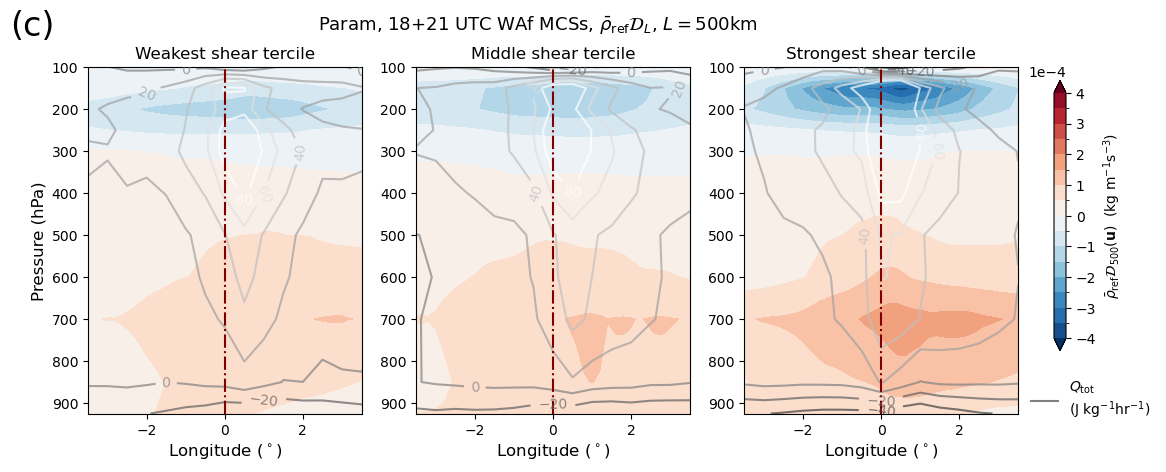

In [71]:
scale=500
ds=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/composites/DY2_CTC_GAL9_MCS_shearTer_n640_L={scale}_isetQ_0p2deg.nc")

fig,axes=plt.subplots(1,3,figsize=(12,4.5))
vmax=0.0004
tlabs=["Weakest","Middle","Strongest"]
for i, tercile in enumerate(["t3","t2","t1"]):
    rho_ref=data_dict["ctc_gal9-density_ref"]
    Cb=(rho_ref*ds["Dl_"+tercile].sel(lat=slice(-1.5,1.5))).mean(dim="lat").plot.contourf(ax=axes[i],levels=17,vmax=vmax,extend="both",add_colorbar=False)
    cQ=(3600*ds["Qtot_"+tercile]).sel(latitude=slice(-1.5,1.5)).mean(dim="latitude").plot.contour(ax=axes[i],levels=np.arange(-80,91,20),cmap="grey",alpha=0.7)
    axes[i].clabel(cQ)    
    axes[i].set_ylim([925,100])
    axes[i].set_xlim([-3.5,3.5])
    axes[i].set_xlabel(r"Longitude ($^\circ$)",fontsize=12)
    axes[i].set_ylabel("")
    axes[i].set_title(tlabs[i]+" shear tercile",fontsize=12)
    axes[i].axvline(0,color="maroon",ls="-.")
axes[0].set_ylabel("Pressure (hPa)",fontsize=12)
fig.suptitle(r"Param, 18+21 UTC WAf MCSs, $\bar\rho_{\rm ref}\mathcal{D}_L$, $L=$%skm"%scale,y=1,fontsize=13)

cax = fig.add_axes([0.93,0.25,0.01,0.6])
cbar=fig.colorbar(Cb, cax = cax, orientation = "vertical", extend = "both")#
#cbar=clb.colorbar
cbar.formatter.set_powerlimits((0, 0)) 
cbar.update_ticks()
cbar.set_label(label=r"$\bar\rho_{\rm ref}\mathcal{D}_{%s}(\mathbf{u})$  (kg m$^{-1}$s$^{-3}$)"%scale,fontsize=10)
fig.legend(handles=[Line2D([],[], color="Grey", label=r"$Q_{\rm tot}$"+"\n(J kg$^{-1}$hr$^{-1}$)")], 
              fontsize=10, bbox_to_anchor=(0.9,0.14), frameon=False ,loc="center left")
fig.text(0.06,0.95,"(c)",fontsize=24)
fig.savefig(f"Figures/MCS_transfer_shear_composites-param.png",dpi=400,bbox_inches="tight",facecolor="white")

FIG S4

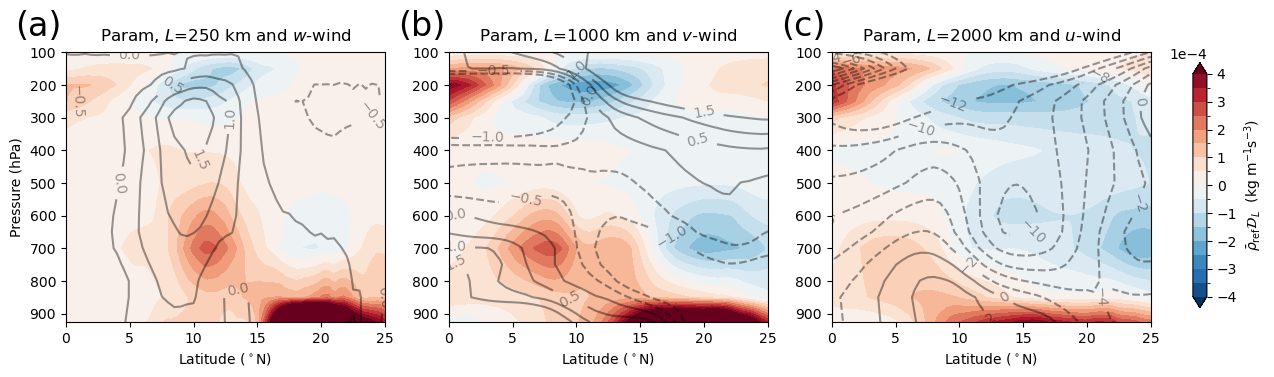

In [72]:
fig,axes=plt.subplots(1,3,figsize=(14,3.5),gridspec_kw={"hspace":0.3})

sim="ctc_gal9"
cont_vars=["upward_air_velocity","y_wind","x_wind"]
for i,l in enumerate([125000,500000,1000000]):
    ax=axes[i]
    cb=(data_dict[sim+"-density_ref"]*data_dict[sim+"-lossett_mean"].Dl_u.sel(length_scale=l,longitude=slice(-50,30))).mean(dim="longitude").plot.contourf(
                                        ax=ax,levels=21,extend="both",vmax=1e-4,add_colorbar=False)
    #                                                    cbar_kwargs={"label":r"$\bar{\rho}_{\rm ref}\mathcal{D}_L$  (kg m$^{-1}$s$^{-3}$)","shrink":0.8,"pad":0.08})
    #cbar=cb.colorbar
    #cbar.formatter.set_powerlimits((0, 0)) 
    #cbar.update_ticks()

    winds=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_{data_dict[sim+"-fstr"]}_dynamics_0p5deg.nc")[cont_vars[i]].mean(dim="time").sel(
                longitude=slice(-50,30)).mean(dim="longitude")
    if i==0:
        Cw,lab_var=(100*winds).plot.contour(ax=ax,levels=[-1,-0.5,0,0.5,1,1.5],colors="k",alpha=0.4),"w"
    elif i==1:
        Cw,lab_var=(winds).plot.contour(ax=ax,levels=[-1,-0.5,0,0.5,1,1.5],colors="k",alpha=0.4),"v"
    elif i==2:
        Cw,lab_var=(winds).plot.contour(ax=ax,levels=np.arange(-12,3,2),colors="k",alpha=0.4),"u"        
    ax.clabel(Cw)
    
    ax.set_ylim([925,100])
    ax.set_xlim([0,25])
    ax.set_title(f"{data_dict[sim+"-tstr"]}, $L$={2*l/1000:.0f} km and ${lab_var}$-wind",pad=8)
    ax.set_ylabel("")
    ax.set_xlabel(r"Latitude ($^\circ$N)")
    ax.text(-4,50,"("+string.ascii_lowercase[i]+")",fontsize=24)
axes[0].set_ylabel("Pressure (hPa)")

cax = fig.add_axes([0.93,0.15,0.01,0.7])
cbar=fig.colorbar(Cb, cax = cax, orientation = "vertical", extend = "both")#
#cbar=clb.colorbar
cbar.formatter.set_powerlimits((0, 0)) 
cbar.update_ticks()
cbar.set_label(label=r"$\bar\rho_{\rm ref}\mathcal{D}_L$  (kg m$^{-1}$s$^{-3}$)",fontsize=10)

fig.savefig("Figures/Zonal_mean_lossett-param.png",dpi=200,bbox_inches="tight",facecolor="white")

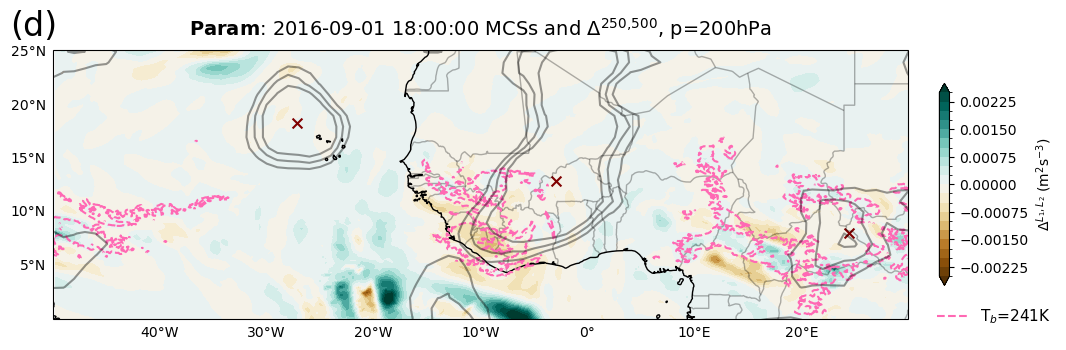

In [73]:
#"""
fig,ax=plt.subplots(figsize=(16,3.5),subplot_kw=dict(projection=ccrs.PlateCarree()),gridspec_kw={"hspace":0.1})

ax.set_extent([-50,30,0,20])
pval,sind=200,10
tstamp=pd.Timestamp("2016-09-01 18:00")

Dl=data_dict["ctc_gal9-lossett_p%03d"%pval].sel(time=tstamp,pressure=pval).Dl_u
(Dl.sel(length_scale=ell_band_MCS[-1]) -Dl.sel(length_scale=ell_band_MCS[0])).plot.contourf(ax=ax,vmax=0.0025,extend="both",cmap="BrBG",levels=21,
                                                        cbar_kwargs={"shrink":0.75,"label":r"$\Delta^{L_1,L_2}$ (m$^2$s$^{-3}$)","pad":0.025})
bt=xr.open_dataset("/gws/ssde/j25b/kscale/DATA/outdir_20160801T0000Z/DMn1280GAL9/channel_n2560_GAL9/single_olwr/20160901_20160801T0000Z_channel_olwr_hourly.nc"
                  ).toa_outgoing_longwave_flux.sel(longitude=slice(-50,30),latitude=slice(0,25)).sel(time=tstamp,method="nearest")
bt=tb_from_olr(bt)
bt.plot.contour(ax=ax,levels=[241],colors="hotpink",linestyles="--",alpha=1)

cv=xr.open_dataset("~/QTrack/CTC_GAL9_curv_vort.nc").curv_vort.sel(time=tstamp,method="nearest")
Cv=cv.plot.contour(ax=ax,levels=[2e-6,4e-6,6e-6],colors="black",alpha=0.4)
data_dict["ctc_gal9-aew_tracks"].sel(time=tstamp).plot.scatter(ax=ax,x="AEW_lon",y="AEW_lat",s=50,color="maroon",marker="x")

ax.coastlines()
ax.add_feature(cfeature.BORDERS,alpha=0.3)
ax.set_title(r"$\rm\mathbf{Param}$: "+str(tstamp)+
             r" MCSs and $\Delta^{250,\!500}$, p=%shPa"%pval,
             fontsize=14,pad=10)
gl=ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
gl.ylines = False
gl.xlines = False

ax.text(-54,26.5,"(d)",fontsize=24)
ax.legend(handles=[Line2D([],[], color="hotpink", ls="--", alpha=1, label=r"T$_b$=241K")], 
               bbox_to_anchor=(1.1,0.01), frameon=False ,loc="center",fontsize=11)
fig.savefig("Figures/Param_spatial_snapshot_MCS_transfer_250-500.png",dpi=200,bbox_inches="tight",facecolor="white")

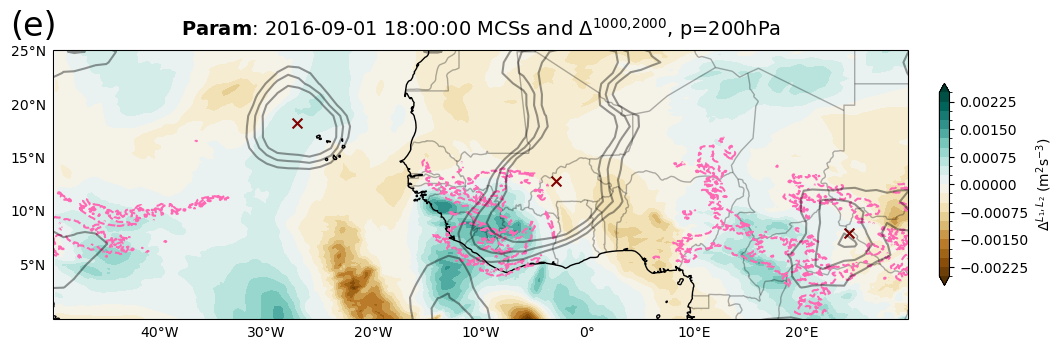

In [74]:
#"""
fig,ax=plt.subplots(figsize=(16,3.5),subplot_kw=dict(projection=ccrs.PlateCarree()),gridspec_kw={"hspace":0.1})

ax.set_extent([-50,30,0,20])
pval,sind=200,10
tstamp=pd.Timestamp("2016-09-01 18:00")

Dl=data_dict["ctc_gal9-lossett_p%03d"%pval].sel(time=tstamp,pressure=pval).Dl_u
(Dl.sel(length_scale=ell_band_L[-1]) -Dl.sel(length_scale=ell_band_L[0])).plot.contourf(ax=ax,vmax=0.0025,extend="both",cmap="BrBG",levels=21,
                                                        cbar_kwargs={"shrink":0.75,"label":r"$\Delta^{L_1,L_2}$ (m$^2$s$^{-3}$)","pad":0.025})
bt=xr.open_dataset("/gws/ssde/j25b/kscale/DATA/outdir_20160801T0000Z/DMn1280GAL9/channel_n2560_GAL9/single_olwr/20160901_20160801T0000Z_channel_olwr_hourly.nc"
                  ).toa_outgoing_longwave_flux.sel(longitude=slice(-50,30),latitude=slice(0,25)).sel(time=tstamp,method="nearest")
bt=tb_from_olr(bt)
bt.plot.contour(ax=ax,levels=[241],colors="hotpink",linestyles="--",alpha=1)
Cv=cv.plot.contour(ax=ax,levels=[2e-6,4e-6,6e-6],colors="black",alpha=0.4)
data_dict["ctc_gal9-aew_tracks"].sel(time=tstamp).plot.scatter(ax=ax,x="AEW_lon",y="AEW_lat",s=50,color="maroon",marker="x")

ax.coastlines()
ax.add_feature(cfeature.BORDERS,alpha=0.3)
ax.set_title(r"$\rm\mathbf{Param}$: "+str(tstamp)+
             r" MCSs and $\Delta^{1000,\!2000}$, p=%shPa"%pval,
             fontsize=14,pad=10)
gl=ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
gl.ylines = False
gl.xlines = False

ax.text(-54,26.5,"(e)",fontsize=24)
#ax.legend(handles=[Line2D([],[], color="hotpink", ls="--", alpha=1, label=r"T$_b$=241K")], 
#               bbox_to_anchor=(1.1,0.01), frameon=False ,loc="center",fontsize=11)
fig.savefig("Figures/Param_spatial_snapshot_MCS_transfer_1000-2000.png",dpi=200,bbox_inches="tight",facecolor="white")

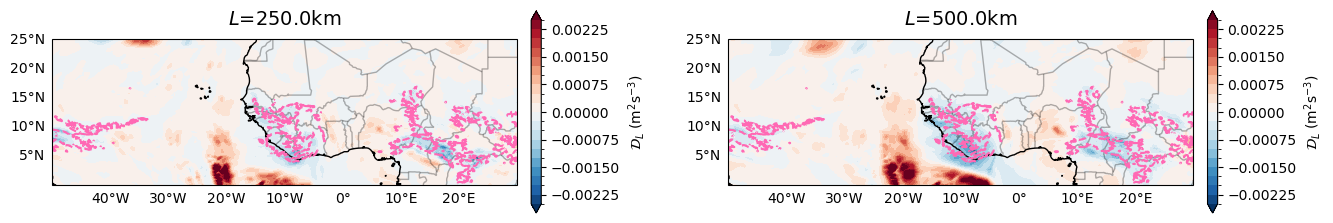

In [75]:
#"""
fig,axes=plt.subplots(1,2,figsize=(16,3.5),subplot_kw=dict(projection=ccrs.PlateCarree()),gridspec_kw={"hspace":0.1})

for i,ax in enumerate(axes):
    ax.set_extent([-50,30,0,20])
    pval,sind=200,10
    tstamp=pd.Timestamp("2016-09-01 18:00")
    
    Dl=data_dict["ctc_gal9-lossett_p%03d"%pval].sel(time=tstamp,pressure=pval).Dl_u
    Dl.sel(length_scale=ell_band_MCS[i]).plot.contourf(ax=ax,vmax=0.0025,extend="both",cmap="RdBu_r",levels=21,
                                                            cbar_kwargs={"shrink":0.75,"label":r"$\mathcal{D}_L$ (m$^2$s$^{-3}$)","pad":0.025})
    bt=xr.open_dataset("/gws/ssde/j25b/kscale/DATA/outdir_20160801T0000Z/DMn1280GAL9/channel_n2560_GAL9/single_olwr/20160901_20160801T0000Z_channel_olwr_hourly.nc"
                      ).toa_outgoing_longwave_flux.sel(longitude=slice(-50,30),latitude=slice(0,25)).sel(time=tstamp,method="nearest")
    bt=tb_from_olr(bt)
    bt.plot.contour(ax=ax,levels=[241],colors="hotpink",linestyles="--",alpha=1)
    #sep_tracks[(sep_tracks.time==tstamp.replace(minute=2)) &
    #            (sep_tracks.area>100)].plot.scatter(ax=ax,x="clon",y="clat",marker="x",color="purple",s=35)
    #ax.legend()
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS,alpha=0.3)
    ax.set_title(f"$L$={2*ell_band_MCS[i]/1000}km",
                 fontsize=14,pad=10)
    gl=ax.gridlines(draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    gl.ylines = False
    gl.xlines = False

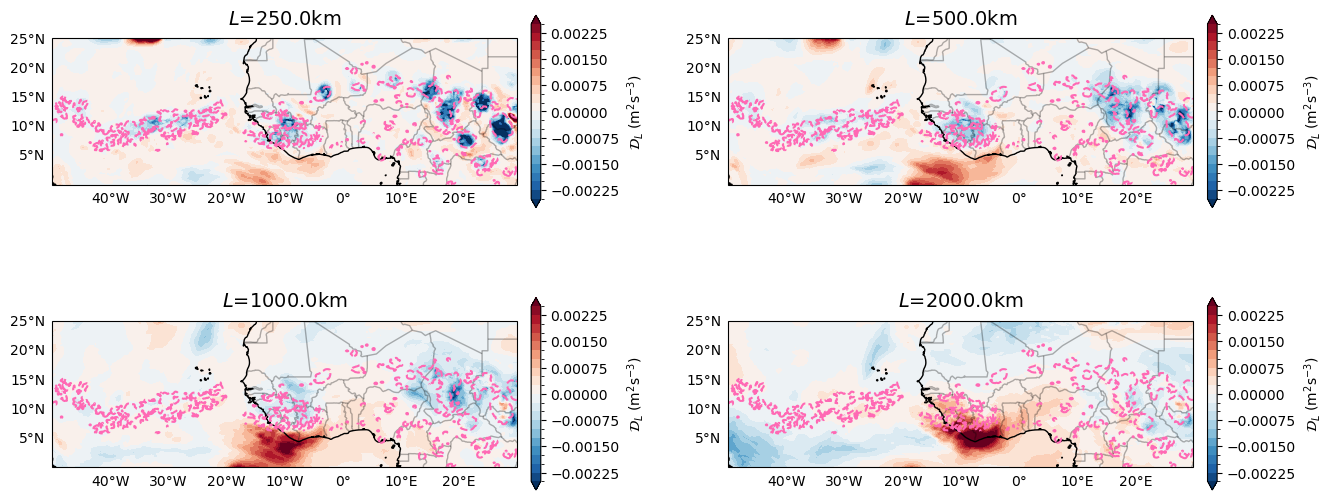

In [76]:
fig,axes=plt.subplots(2,2,figsize=(16,7),subplot_kw=dict(projection=ccrs.PlateCarree()),gridspec_kw={"hspace":0.1})

for i, ax in enumerate(axes.flatten()):
    ax.set_extent([-50,30,0,20])
    pval,sind=200,10
    tstamp=pd.Timestamp("2016-09-01 18:00")
    
    Dl=data_dict["ctc_ral3-lossett_p%03d"%pval].sel(time=tstamp,pressure=pval).Dl_u
    if i<2:
        l=ell_band_MCS[i]
    else:
        l=ell_band_L[i-2]
    Dl.sel(length_scale=l).plot.contourf(ax=ax,vmax=0.0025,extend="both",cmap="RdBu_r",levels=21,
                                                            cbar_kwargs={"shrink":0.75,"label":r"$\mathcal{D}_L$ (m$^2$s$^{-3}$)","pad":0.025})
    bt=xr.open_dataset("/gws/ssde/j25b/kscale/DATA/outdir_20160801T0000Z/DMn1280GAL9/channel_n2560_RAL3p2/single_olwr/20160901_20160801T0000Z_channel_olwr_hourly.nc"
                      ).toa_outgoing_longwave_flux.sel(longitude=slice(-50,30),latitude=slice(0,25)).sel(time=tstamp,method="nearest")
    bt=tb_from_olr(bt)
    bt.plot.contour(ax=ax,levels=[241],colors="hotpink",linestyles="--",alpha=1)
    #sep_tracks[(sep_tracks.time==tstamp.replace(minute=2)) &
    #            (sep_tracks.area>100)].plot.scatter(ax=ax,x="clon",y="clat",marker="x",color="purple",s=35)
    #ax.legend()
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS,alpha=0.3)
    ax.set_title(f"$L$={2*l/1000}km",
                 fontsize=14,pad=10)
    gl=ax.gridlines(draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    gl.ylines = False
    gl.xlines = False

FIG S5

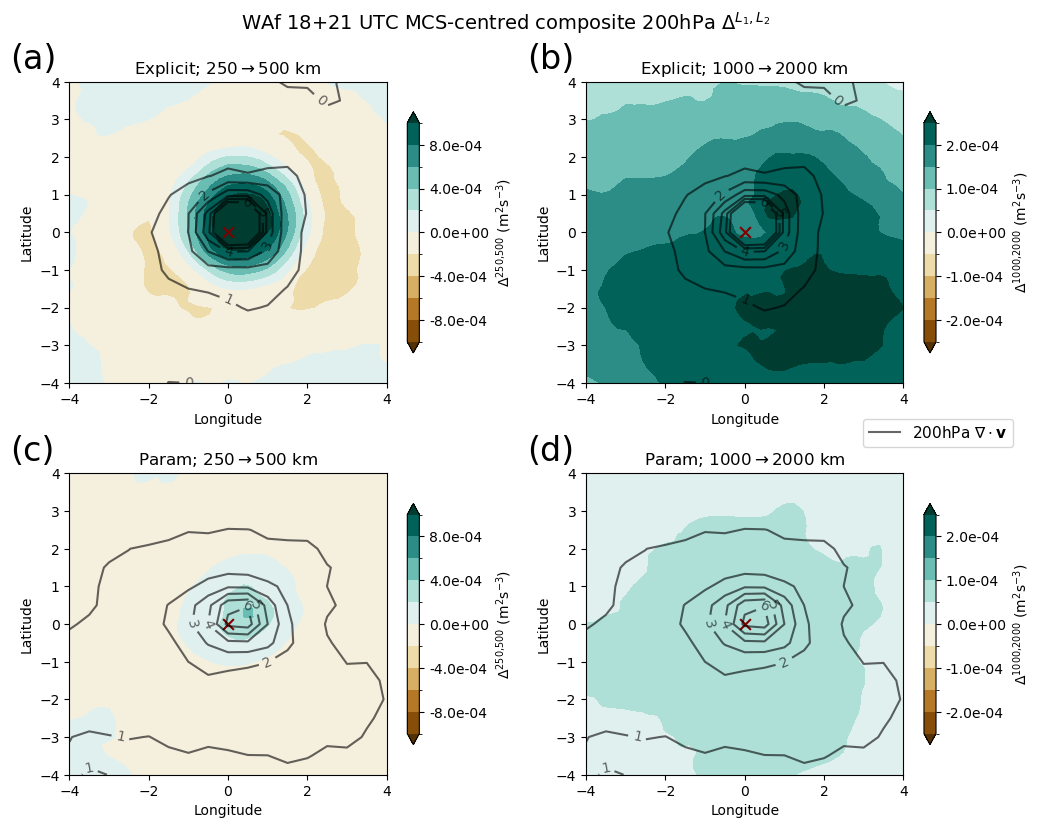

In [77]:
fig,axes=plt.subplots(2,2,figsize=(12,9),gridspec_kw={"hspace":0.3,"wspace":0.25})
axes=axes.flatten()

ds=xr.open_dataset("/gws/ssde/j25b/lmcs/bmaybee/aew_work/composites/DY2_CTC_RAL3p2_MCS_deltaIset_0p2deg.nc")
div=xr.open_dataset("/gws/ssde/j25b/lmcs/bmaybee/aew_work/composites/DY2_CTC_RAL3p2_MCS_dynamics_0p5deg.nc").horizontal_divergence_mean
ds["deltaDl_250-500"].sel(pressure=200).plot.contourf(ax=axes[0],cmap="BrBG",vmax=0.001,levels=11,extend="both",
                                                      cbar_kwargs={"label":r"$\Delta^{250,\!500}$ (m$^2$s$^{-3}$)","shrink":0.8,"format":"%.1e"})
Cd=div.sel(pressure=200).plot.contour(ax=axes[0],colors="k",levels=np.arange(-4e-5,7e-5,1e-5),alpha=0.6)
axes[0].clabel(Cd)
axes[0].set_title(r"Explicit; 250$\rightarrow$500 km",fontsize=12)

ds["deltaDl_1000-2000"].sel(pressure=200).plot.contourf(ax=axes[1],cmap="BrBG",vmax=0.00025,vmin=-0.00025,levels=11,extend="both",
                                                      cbar_kwargs={"label":r"$\Delta^{1000,\!2000}$ (m$^2$s$^{-3}$)","shrink":0.8,"format":"%.1e"})
Cd=div.sel(pressure=200).plot.contour(ax=axes[1],colors="k",levels=np.arange(-4e-5,7e-5,1e-5),alpha=0.6)
axes[1].clabel(Cd)
axes[1].set_title(r"Explicit; 1000$\rightarrow$2000 km",fontsize=12)

ds=xr.open_dataset("/gws/ssde/j25b/lmcs/bmaybee/aew_work/composites/DY2_CTC_GAL9_MCS_deltaIset_0p2deg.nc")
div=xr.open_dataset("/gws/ssde/j25b/lmcs/bmaybee/aew_work/composites/DY2_CTC_GAL9_MCS_dynamics_0p5deg.nc").horizontal_divergence_mean
ds["deltaDl_250-500"].sel(pressure=200).plot.contourf(ax=axes[2],cmap="BrBG",vmax=0.001,levels=11,extend="both",
                                                      cbar_kwargs={"label":r"$\Delta^{250,\!500}$ (m$^2$s$^{-3}$)","shrink":0.8,"format":"%.1e"})
Cd=div.sel(pressure=200).plot.contour(ax=axes[2],colors="k",levels=np.arange(-4e-5,7e-5,1e-5),alpha=0.6)
axes[2].clabel(Cd)

axes[2].set_title(r"Param; 250$\rightarrow$500 km",fontsize=12)
ds["deltaDl_1000-2000"].sel(pressure=200).plot.contourf(ax=axes[3],cmap="BrBG",vmax=0.00025,vmin=-0.00025,levels=11,extend="both",
                                                      cbar_kwargs={"label":r"$\Delta^{1000,\!2000}$ (m$^2$s$^{-3}$)","shrink":0.8,"format":"%.1e"})
Cd=div.sel(pressure=200).plot.contour(ax=axes[3],colors="k",levels=np.arange(-4e-5,7e-5,1e-5),alpha=0.6)
axes[3].clabel(Cd)
axes[3].set_title(r"Param; 1000$\rightarrow$2000 km",fontsize=12)

for i,ax in enumerate(axes):
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect(0.95)
    ax.text(-5.5,4.35,f"({string.ascii_lowercase[i]})",fontsize=24)
    ax.scatter(0,0,marker="x",s=60,color="maroon")
fig.suptitle(r"WAf 18+21 UTC MCS-centred composite 200hPa $\Delta^{L_1,L_2}$",fontsize=14,y=0.96)
fig.legend(handles=[Line2D([],[],color="k", alpha=0.6, marker="", label=r'200hPa $\nabla\cdot\mathbf{v}$')], 
               fontsize='11', ncols=3, loc="center", bbox_to_anchor=(0.86,0.49))
fig.savefig(f"Figures/SuppFig_bandIset_MCS_composites.png",dpi=400,bbox_inches="tight",facecolor="white")

FIG S6 - Explicit AEW PV plots, in main figure collection

FIG S7

In [78]:
sim="ctc_gal9"
eke=1/2 * (data_dict[sim+"-filt_pert_tm"].x_wind**2 + data_dict[sim+"-filt_pert_tm"].y_wind**2)
deke_dt = eke.differentiate("time")

In [79]:
tm = data_dict[sim+"-filt"].mean(dim="longitude")

In [80]:
Deke_Dt = deke_dt + (
                mpcalc.advection(eke,u=tm.x_wind.metpy.quantify(),v=tm.y_wind.metpy.quantify()
                                ).metpy.dequantify()
                + mpcalc.advection(eke,u=data_dict[sim+"-filt_pert_tm"].x_wind.metpy.quantify(),v=data_dict[sim+"-filt_pert_tm"].y_wind.metpy.quantify()
                                  ).metpy.dequantify())

In [81]:
aew_Deke_Dt=(data_dict[sim+"-density_ref"].sel(pressure=slice(600,750))[::-1]*Deke_Dt.sel(pressure=slice(750,600))).mean(dim="pressure")

In [82]:
case_aew_gal9=data_dict[sim+"-aew_tracks"].sel(system=10)
case_aew_gal9=case_aew_gal9.where((case_aew_gal9.AEW_strength>0) & (case_aew_gal9.AEW_lon<30) & (case_aew_gal9.AEW_lon>-30)
                        ,drop=True)

0.0001626435514176806 -0.0005255933597956406 -8.143416503921658e-05
0.0001626435514176806 -0.000578835659128091 -8.865068685825745e-06
0.0001626435514176806 -0.00010987939629292162 -5.4475488711853297e-05


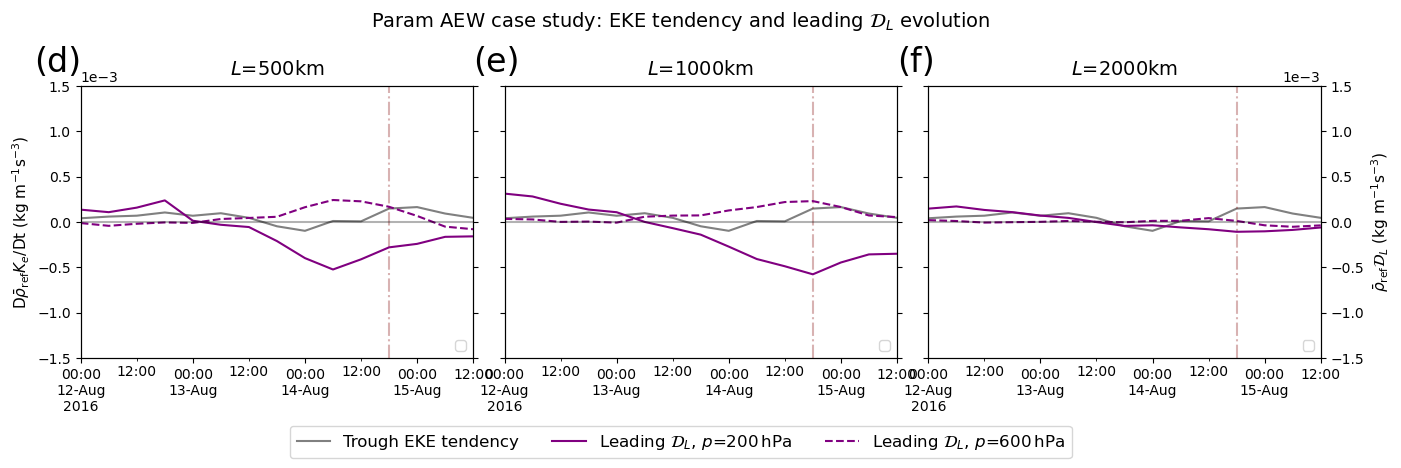

In [83]:
fig,axes=plt.subplots(1,3,figsize=(16,4),gridspec_kw={"wspace":0.08})

for j,scale in enumerate([250,500,1000]):
    eke_vals,lossett200_vals,lossett600_vals=[],[],[]
    for i, tstamp in enumerate(case_aew_gal9.time):
        wave_eke=Deke_Dt.sel(time=tstamp)
        wave_lossett200,wave_lossett600=data_dict[sim+"-lossett_p200"].Dl_u.sel(time=tstamp,length_scale=scale*1000),data_dict[sim+"-lossett_p600"].Dl_u.sel(time=tstamp,length_scale=scale*1000)
        dists = xr.apply_ufunc(haversine,wave_eke.longitude,wave_eke.latitude,case_aew_gal9.AEW_lon.values[i],case_aew_gal9.AEW_lat.values[i])
        dists = (dists/dists).where(dists<=300).fillna(0).T
        eke_vals.append(float(wave_eke.where(dists!=0).mean()))
        
        dists = xr.apply_ufunc(haversine,wave_lossett200.longitude,wave_lossett200.latitude,case_aew_gal9.AEW_lon.values[i] - 2,case_aew_gal9.AEW_lat.values[i])
        dists = (dists/dists).where(dists<=300).fillna(0).T
        lossett200_vals.append(float(data_dict[sim+"-density_ref"].sel(pressure=200)*wave_lossett200.where(dists!=0).mean()))
        lossett600_vals.append(float(data_dict[sim+"-density_ref"].sel(pressure=600)*wave_lossett600.where(dists!=0).mean()))

    ax=axes[j]
    pd.Series(eke_vals,case_aew_gal9.time).plot(ax=ax,color="grey")
    ax1=ax.twinx()
    rstr=get_corr_str(eke_vals,lossett200_vals)
    pd.Series(lossett200_vals,case_aew_gal9.time).plot(ax=ax1,color="purple",label=rstr)
    rstr=get_corr_str(eke_vals,lossett600_vals)
    pd.Series(lossett600_vals,case_aew_gal9.time).plot(ax=ax1,color="purple",ls="--",label=rstr)
    #pearsonr200=stats.pearsonr(eke_vals,lossett200_vals)
    #pearsonr600=stats.pearsonr(eke_vals,lossett600_vals)
    ax.set_title(f"$L$={2*scale:.0f}km",fontsize=14,pad=8)#; r={pearsonr200.statistic:.2f}/{pearsonr600.statistic:.2f} ({pearsonr200.pvalue:.2f}/{pearsonr600.pvalue:.2f})")
    ax1.legend(loc="lower right")
    ax.ticklabel_format(scilimits=[-2,3],axis="y")
    ax1.ticklabel_format(scilimits=[-2,3],axis="y")
    ax1.set_ylim([-1.5e-3,1.5e-3])
    ax.set_ylim([-1.5e-3,1.5e-3])
    ax1.axhline(0,color="k",alpha=0.3)
    ax.axvline("2016-08-14 18:00",color="maroon",ls="-.",alpha=0.3)
    ax.axvline("2016-08-16 12:00",color="maroon",ls="-.",alpha=0.3)
    ax.axvline("2016-08-18 06:00",color="maroon",ls="-.",alpha=0.3)
    if j>0:
        ax.set_yticklabels("")
        ax.text(-0.08,1.05,f"({string.ascii_lowercase[j+3]})",fontsize=24,transform=ax.transAxes)
    if j<2:
        ax1.set_yticklabels("")
    print(max(eke_vals),min(lossett200_vals),min(lossett600_vals))
axes[0].set_ylabel(r"D$\bar\rho_{\rm ref}K_e$/Dt (kg m$^{-1}$s$^{-3}$)",fontsize=11)
axes[0].text(-0.12,1.05,f"(d)",fontsize=24,transform=axes[0].transAxes)
ax1.set_ylabel(r"$\bar\rho_{\rm ref}\mathcal{D}_L$ (kg m$^{-1}$s$^{-3}$)",fontsize=11)

legend_elements = [Line2D([],[],color="grey", marker="", label="Trough EKE tendency"),
                   Line2D([],[],color="purple", marker="", label=r"Leading $\mathcal{D}_L$, $p$=200$\,$hPa"),
                   Line2D([],[],color="purple", ls="--", marker="", label=r"Leading $\mathcal{D}_L$, $p$=600$\,$hPa")]
fig.subplots_adjust(bottom=0.2)
fig.legend(handles=legend_elements, ncol=3, bbox_to_anchor=(0.5,-0.01), loc="center",fontsize=12)
fig.suptitle(r"Param AEW case study: EKE tendency and leading $\mathcal{D}_L$ evolution",fontsize=14,y=1.07) 
fig.savefig("Figures/Param_case_study_energetics.png",dpi=400,bbox_inches="tight",facecolor="white")